# Trabajo Práctico Integrador — Decision Intelligence Capstone
## Dejar de fumar: ¿cuánto peso se gana y quién está en riesgo? Predicción, inferencia y causalidad con NHEFS

**Asignatura:** Estadística Aplicada y Modelos de Regresión (EAyMR 2026) · UCA — Facultad de Ingeniería y Ciencias Agrarias
**Autor:** Camilo Garcia Placeres
**Roles Scrum:** proyecto individual; el autor asume los cuatro roles (Project Lead, Backend/ML-Causal, Frontend, QA). Ver `BITACORA.md`.
**Semilla global:** `SEED = 42` · **Dataset:** NHEFS — *NHANES I Epidemiologic Follow-up Study* (1971–1992), N = 1.629, 64 variables.

> **Declaración de uso de IA generativa.** Este proyecto se desarrolló con asistencia de un modelo de IA (Claude, Anthropic) para escribir código, redactar y revisar. El detalle de qué se delegó, qué errores de la IA se detectaron y qué pruebas determinísticas se escribieron para controlarlos está en la Entrada 5 de `BITACORA.md`.

### Índice
0. [Marco del problema y preguntas de decisión](#fase0)
1. [FASE 1 — Inferencia estadística clásica, contrastes y ANOVA](#fase1)
2. [FASE 2 — Gauss-Markov, puntos influyentes, VIF y PCA sin *leakage*](#fase2)
3. [FASE 3 — Torneo predictivo, calibración y explicabilidad](#fase3)
4. [FASE 4 — Inferencia causal: DAG, *backdoor*, DoWhy, Double ML y refutaciones](#fase4)
5. [Ensayo crítico: capacidad predictiva vs. palanca causal](#ensayo)
6. [Conclusiones, recomendaciones y limitaciones](#conclusiones)
7. [Referencias](#referencias)

In [1]:
import sys, warnings, logging
from pathlib import Path
warnings.filterwarnings("ignore")
logging.getLogger("dowhy").setLevel(logging.ERROR)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import TTestIndPower

from nhefs import data, features, causal, pipeline
from nhefs.config import (SEED, TREATMENT, OUTCOME_CAUSAL, OUTCOME_PRED, CONFOUNDERS, EFFECT_MODIFIERS,
                          INSTRUMENT, COLLIDER, PCA_VARS, NUM_PRED, BIN_PRED)

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.dpi"] = 100
ALPHA = 0.05   # nivel de significación fijado a priori para todo el trabajo
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/claude/tpi


<a id="fase0"></a>
---
# 0. Marco del problema y preguntas de decisión


**Contexto operativo.** Una agencia de salud pública diseña un programa de cesación tabáquica para adultos fumadores. Hay dos obstáculos concretos:
1. **El miedo a engordar** es una de las razones más citadas para no dejar de fumar o para recaer. Para diseñar el componente de apoyo nutricional y comunicar expectativas realistas, el programa necesita saber **cuánto peso causa dejar de fumar**, no cuánto peso ganan quienes dejan (son preguntas distintas).
2. **El presupuesto es limitado.** Conviene priorizar a los fumadores con mayor **riesgo de muerte** en la próxima década, usando información que se pueda relevar en una entrevista inicial.

**Preguntas de decisión**

| | Pregunta | Tipo | Cantidad objetivo |
|---|---|---|---|
| P1 | ¿Qué fumadores tienen mayor probabilidad de morir en los próximos 10 años? | Predictiva | $P(death = 1 \mid X)$ |
| P2 | ¿Cuántos kg más gana una persona si deja de fumar, frente a si sigue fumando? | Causal | $E[Y \mid do(T=1)] - E[Y \mid do(T=0)]$ |
| P3 | ¿El aumento de peso es mayor en los fumadores más intensos o en los más jóvenes? | Causal (heterogeneidad) | $\tau(x) = E[Y(1) - Y(0) \mid X = x]$ |

**Hipótesis adicionales a las de la consigna**
- **H-a (autoselección):** quienes dejaron de fumar no son comparables con quienes siguieron (difieren en edad e intensidad de consumo antes del tratamiento).
- **H-b (efecto metabólico de la nicotina):** el aumento de peso es mayor cuanto más se fumaba.
- **H-c ("*sick quitter*"):** la mayor mortalidad observada entre quienes dejaron de fumar no es un efecto causal de dejar, sino de quiénes dejan (personas mayores o que dejan por un diagnóstico).

**Restricciones reales del sistema:** los datos son observacionales (no hubo asignación aleatoria); el 3,9% de los participantes no tiene el peso de 1982 (censura); a mitad del estudio cambió el cuestionario; no hay datos de dieta (el mediador principal no está medido); y la muestra es de adultos de EE. UU. de los años 70, lo que limita la validez externa.

In [2]:
df_raw = data.load_raw(ROOT / "data" / "raw" / "nhefs.csv")
codebook = pd.read_csv(ROOT / "data" / "raw" / "NHEFS_codebook.csv")
print(f"Dimensiones: {df_raw.shape[0]} participantes x {df_raw.shape[1]} variables")

roles = pd.DataFrame([
    ("qsmk", "Tratamiento T", "Binaria", "Dejó de fumar entre 1971 y 1982"),
    ("wt82_71", "Resultado causal Y", "Continua (kg)", "Cambio de peso 1971 → 1982"),
    ("death", "Resultado predictivo", "Binaria", "Muerte entre 1983 y 1992"),
    ("sex, race", "Confusores Z", "Binarias nominales", "Sexo, raza"),
    ("age, smokeyrs, smokeintensity, wt71", "Confusores Z", "Continuas / discretas", "Edad, años fumando, cigarrillos/día, peso 1971"),
    ("education, exercise, active", "Confusores Z", "Ordinales (codificadas)", "Educación (1–5), ejercicio (0–2), actividad diaria (0–2)"),
    ("price82, tax82", "Instrumento candidato", "Continuas (US$ 2008)", "Precio e impuesto al tabaco en el estado (1982)"),
    ("sbp, dbp", "Colisionador C (post-tratamiento)", "Continuas (mmHg)", "Presión arterial medida en 1982"),
    ("ht, cholesterol, income, alcohol…, dx clínicos", "Predictoras basales", "Mixtas", "Altura, colesterol, ingreso, alcohol, 20 antecedentes clínicos"),
], columns=["Variable(s)", "Rol", "Escala", "Descripción"])
roles.style.hide(axis="index")

Dimensiones: 1629 participantes x 64 variables


Variable(s),Rol,Escala,Descripción
qsmk,Tratamiento T,Binaria,Dejó de fumar entre 1971 y 1982
wt82_71,Resultado causal Y,Continua (kg),Cambio de peso 1971 → 1982
death,Resultado predictivo,Binaria,Muerte entre 1983 y 1992
"sex, race",Confusores Z,Binarias nominales,"Sexo, raza"
"age, smokeyrs, smokeintensity, wt71",Confusores Z,Continuas / discretas,"Edad, años fumando, cigarrillos/día, peso 1971"
"education, exercise, active",Confusores Z,Ordinales (codificadas),"Educación (1–5), ejercicio (0–2), actividad diaria (0–2)"
"price82, tax82",Instrumento candidato,Continuas (US$ 2008),Precio e impuesto al tabaco en el estado (1982)
"sbp, dbp",Colisionador C (post-tratamiento),Continuas (mmHg),Presión arterial medida en 1982
"ht, cholesterol, income, alcohol…, dx clínicos",Predictoras basales,Mixtas,"Altura, colesterol, ingreso, alcohol, 20 antecedentes clínicos"


<a id="fase1"></a>
---
# FASE 1 — Inferencia estadística clásica, contrastes y ANOVA

## 1.1 Auditoría forense de datos (DGP)

In [3]:
auditoria = data.audit(df_raw)
display(auditoria.style.format({"pct": "{:.1f}%"}).hide(axis="index"))
d = data.clean(df_raw)

bloque = d["bloque_no_informado"] == 1
print(f"Bloque de 5 variables clínicas con código 2 ('MISSING'): {bloque.sum()} participantes")
print(f"  seqn de esos participantes: {d.loc[bloque, 'seqn'].min()} a {d.loc[bloque, 'seqn'].max()}"
      f"  |  resto: {d.loc[~bloque, 'seqn'].min()} a {d.loc[~bloque, 'seqn'].max()}")
print(f"  ¿se superponen los rangos de seqn? {d.loc[bloque, 'seqn'].min() <= d.loc[~bloque, 'seqn'].max()}")
print(f"pregnancies faltante: hombres {d.loc[d.sex == 0, 'pregnancies'].isna().mean():.0%} | mujeres {d.loc[d.sex == 1, 'pregnancies'].isna().mean():.0%}")
print(f"alcoholhowmuch faltante entre quienes no bebieron (alcoholpy = 0): {d.loc[d.alcoholpy == 0, 'alcoholhowmuch'].isna().mean():.0%}")

variable,tipo,casos,pct
yrdth,NaN explícito,1311,80.5%
modth,NaN explícito,1307,80.2%
dadth,NaN explícito,1307,80.2%
pregnancies,NaN explícito,903,55.4%
birthcontrol,código 2 = 'MISSING' (oculto),806,49.5%
pica,código 2 = 'MISSING' (oculto),791,48.6%
boweltrouble,código 2 = 'MISSING' (oculto),791,48.6%
hbp,código 2 = 'MISSING' (oculto),791,48.6%
diabetes,código 2 = 'MISSING' (oculto),791,48.6%
hbpmed,código 2 = 'MISSING' (oculto),791,48.6%


Bloque de 5 variables clínicas con código 2 ('MISSING'): 791 participantes
  seqn de esos participantes: 20751 a 25061  |  resto: 233 a 20745
  ¿se superponen los rangos de seqn? False
pregnancies faltante: hombres 100% | mujeres 13%
alcoholhowmuch faltante entre quienes no bebieron (alcoholpy = 0): 100%


**Mecanismo del faltante en el resultado causal.** El peso de 1982 falta en 63 participantes (3,9%): son **censurados** (no volvieron a la medición de 1982). Comparo sus características basales con las de los observados y estimo un modelo logístico de la probabilidad de censura.

In [4]:
cmp = data.missing_vs_observed(d, "censurado", ["age", "wt71", "smokeintensity", "smokeyrs", "qsmk", "sex", "race", "education"])
display(cmp.style.format("{:.3f}"))
m_cens = smf.logit("censurado ~ qsmk + sex + race + age + education + smokeintensity + smokeyrs + exercise + active + wt71", d).fit(disp=0)
print(m_cens.summary2().tables[1][["Coef.", "P>|z|"]].round(4).to_string())
print(f"\nTest LR global del modelo de censura: χ² = {m_cens.llr:.2f}, gl = {int(m_cens.df_model)}, p = {m_cens.llr_pvalue:.4f}")
print(f"Tasa de muerte entre censurados: {d.loc[d.censurado == 1, 'death'].mean():.1%} vs. observados {d.loc[d.censurado == 0, 'death'].mean():.1%}")

,media con faltante,media sin faltante,diferencia,p-valor (Welch)
variable,,,,
age,50.270,43.660,6.610,0.001
wt71,76.551,70.831,5.720,0.058
smokeintensity,21.190,20.526,0.665,0.683
smokeyrs,31.905,24.588,7.317,0.000
qsmk,0.397,0.257,0.139,0.031
sex,0.413,0.513,-0.101,0.119
race,0.143,0.132,0.011,0.803
education,2.429,2.715,-0.286,0.077


                 Coef.  P>|z|
Intercept      -6.3292 0.0000
qsmk            0.5012 0.0691
sex             0.1182 0.6981
race            0.1017 0.8020
age             0.0133 0.5557
education      -0.0766 0.5177
smokeintensity  0.0060 0.6027
smokeyrs        0.0324 0.1421
exercise       -0.2356 0.2261
active          0.2384 0.2473
wt71            0.0208 0.0106

Test LR global del modelo de censura: χ² = 33.84, gl = 10, p = 0.0002
Tasa de muerte entre censurados: 42.9% vs. observados 18.6%


### 1.1 · Clasificación del mecanismo de faltantes y estrategia


| Variable(s) | Faltantes | Mecanismo | Evidencia | Estrategia |
|---|---|---|---|---|
| `diabetes`, `hbp`, `hbpmed`, `pica`, `boweltrouble` (código 2 oculto) | 791 (48,6%) | **MCAR respecto de la salud** (faltante por diseño) | Coinciden **exactamente** con los participantes de `seqn` ≥ 20.751: es un cambio de versión del cuestionario, y depende solo de un identificador administrativo | Categoría explícita `no_informado` (no se imputan diagnósticos inexistentes) |
| `pregnancies` | 903 | **Estructural** (no aplica) | 100% de los hombres | Se excluye |
| `alcoholhowmuch` | 417 | **Estructural** | 100% de quienes no bebieron en el último año | Se usa `alcoholfreq` |
| `wt82` / `wt82_71` (resultado causal) | 63 (3,9%) | **MAR condicional a las covariables**, con **riesgo de MNAR** | La censura depende del peso inicial (p = 0,011) y el modelo global es significativo (LR p = 0,0002): no es MCAR. Los censurados murieron más (42,9% vs. 18,6%) y eran más grandes y mayores | Análisis de casos completos + **IPCW** como sensibilidad (Fase 4) |
| `income`, `cholesterol` | 62 / 16 | MAR plausible | < 4% | Imputación por mediana **dentro del Pipeline** (ajustada solo en train) |
| `price82`, `tax82` | 92 | MAR (estado de residencia desconocido) | Coincide con `birthplace` faltante | Casos completos, solo en el análisis de instrumento |

**Justificación matemática.** Bajo **MCAR**, la muestra completa es una submuestra aleatoria y cualquier estimador consistente sigue siéndolo. Bajo **MAR** ($R \perp\!\!\!\perp Y \mid X$), el análisis de casos completos sesga las medias marginales, pero ponderar cada caso observado por $1/\pi(X)$, con $\pi(X) = P(R = 1 \mid X)$, recupera el valor poblacional: $E[Y] = E\big[R\,Y/\pi(X)\big]$. Eso es lo que hace IPCW. Bajo **MNAR**, ninguna corrección basada en lo observado alcanza: queda como limitación explícita.

## 1.2 Exploración: distribuciones y correlaciones

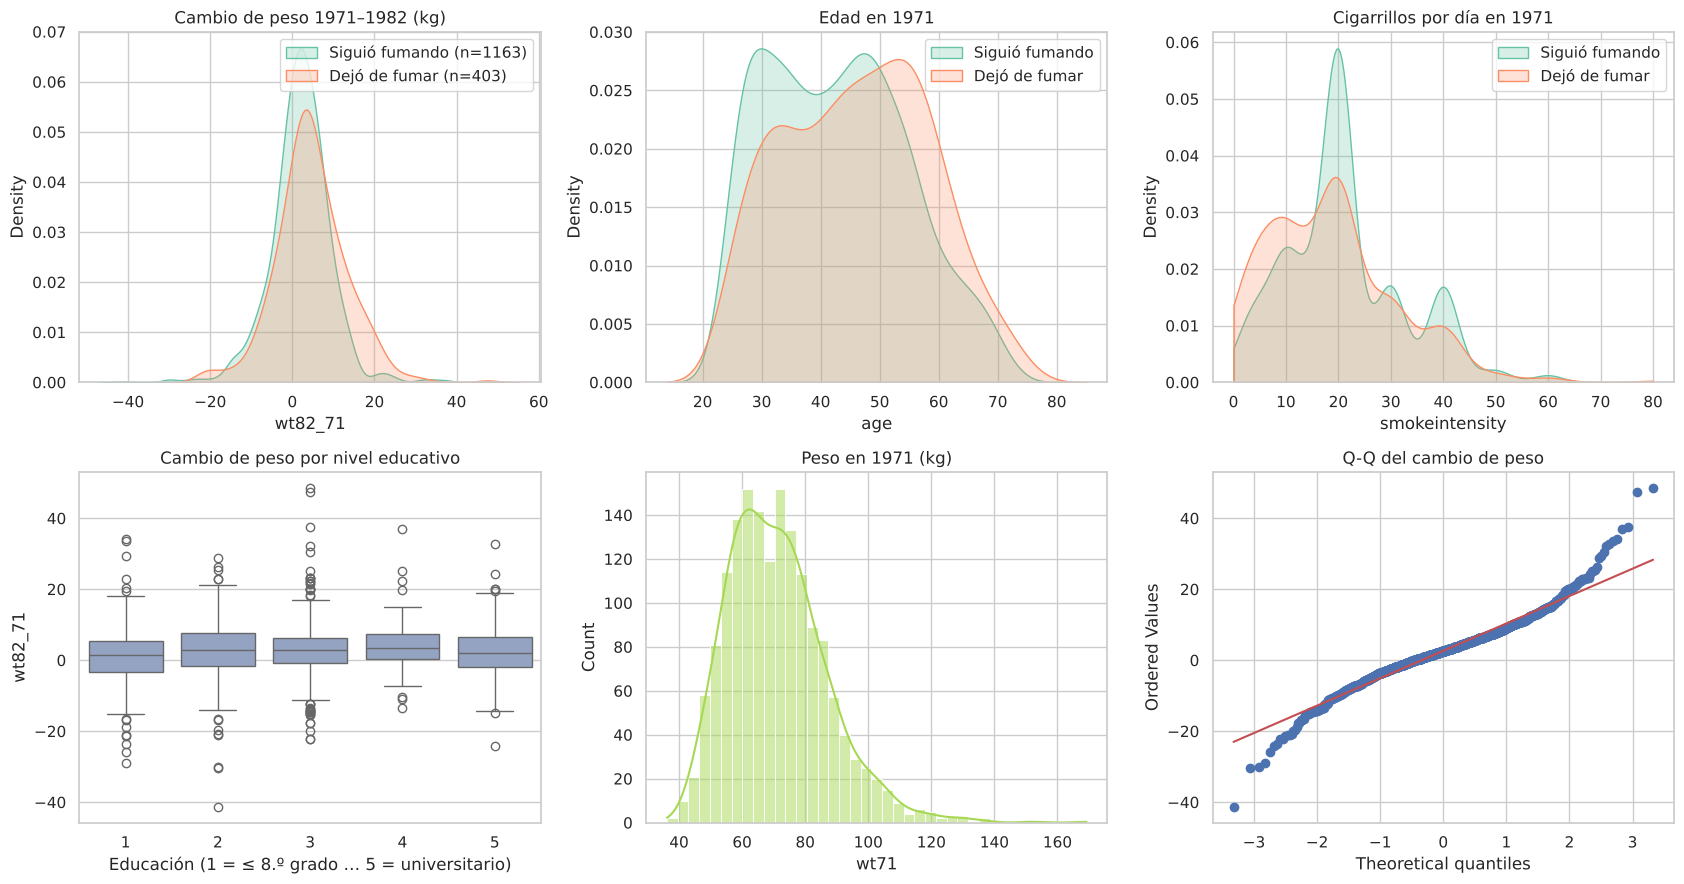

Cambio de peso: media 2.64 kg, mediana 2.60, asimetría 0.20, curtosis (exceso) 3.72


In [5]:
dc = data.causal_sample(d)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for t, col, lab in [(0, "#66c2a5", "Siguió fumando"), (1, "#fc8d62", "Dejó de fumar")]:
    s = dc[dc[TREATMENT] == t]
    sns.kdeplot(s[OUTCOME_CAUSAL], ax=axes[0, 0], fill=True, color=col, label=f"{lab} (n={len(s)})")
    sns.kdeplot(s["age"], ax=axes[0, 1], fill=True, color=col, label=lab)
    sns.kdeplot(s["smokeintensity"], ax=axes[0, 2], fill=True, color=col, label=lab, clip=(0, 80))
axes[0, 0].set_title("Cambio de peso 1971–1982 (kg)"); axes[0, 0].legend()
axes[0, 1].set_title("Edad en 1971"); axes[0, 1].legend()
axes[0, 2].set_title("Cigarrillos por día en 1971"); axes[0, 2].legend()
sns.boxplot(data=dc, x="education", y=OUTCOME_CAUSAL, ax=axes[1, 0], color="#8da0cb")
axes[1, 0].set_title("Cambio de peso por nivel educativo"); axes[1, 0].set_xlabel("Educación (1 = ≤ 8.º grado … 5 = universitario)")
sns.histplot(d["wt71"], kde=True, ax=axes[1, 1], color="#a6d854"); axes[1, 1].set_title("Peso en 1971 (kg)")
stats.probplot(dc[OUTCOME_CAUSAL], dist="norm", plot=axes[1, 2]); axes[1, 2].set_title("Q-Q del cambio de peso")
plt.tight_layout(); plt.show()
print(f"Cambio de peso: media {dc[OUTCOME_CAUSAL].mean():.2f} kg, mediana {dc[OUTCOME_CAUSAL].median():.2f}, "
      f"asimetría {stats.skew(dc[OUTCOME_CAUSAL]):.2f}, curtosis (exceso) {stats.kurtosis(dc[OUTCOME_CAUSAL]):.2f}")

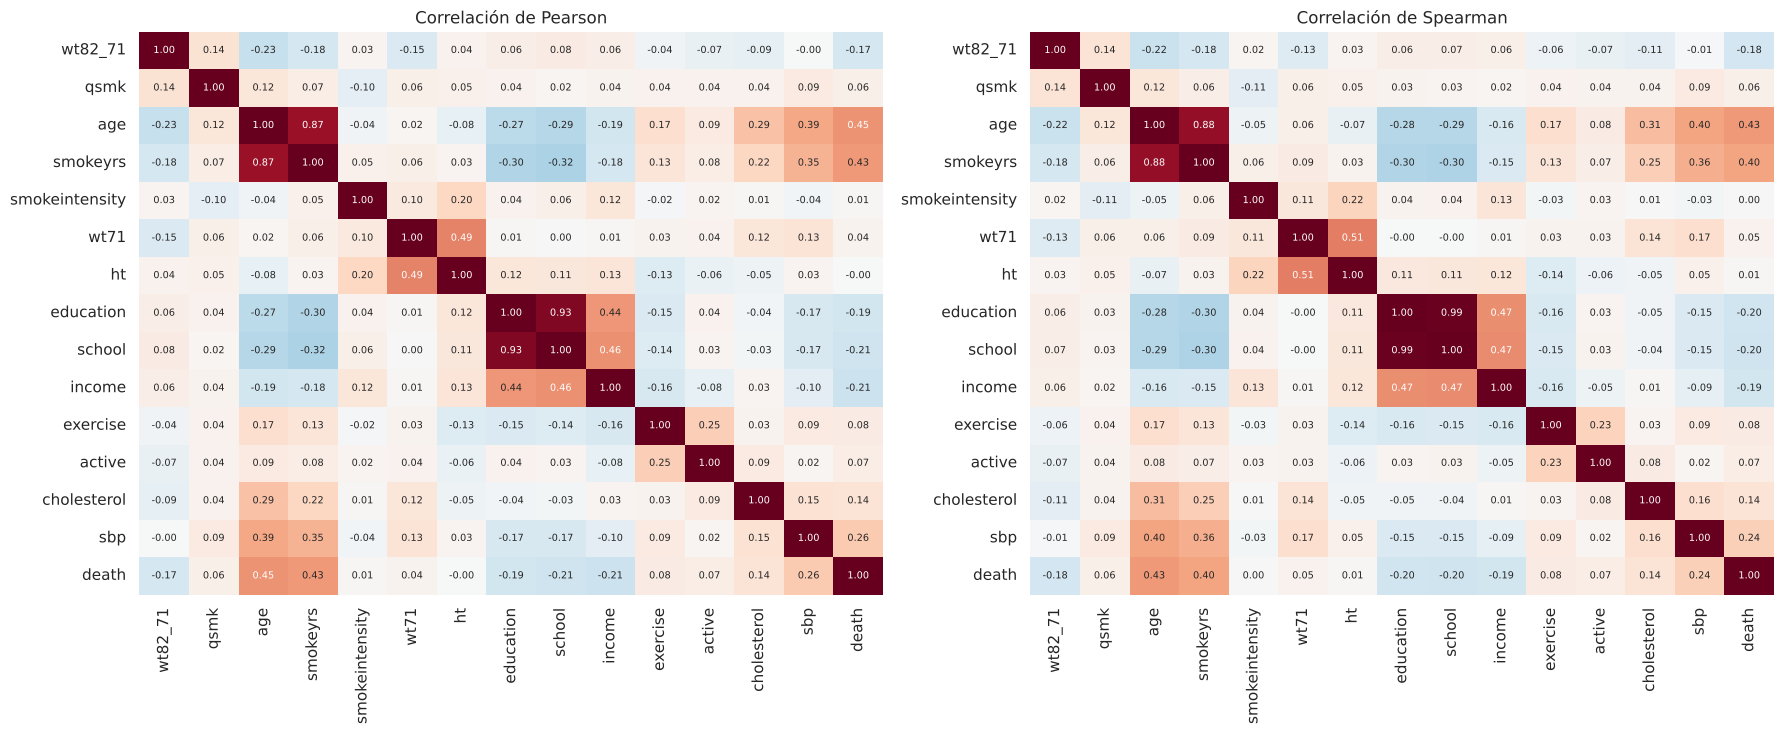

Mayor diferencia Spearman − Pearson: education vs school (0.06)


In [6]:
vars_corr = [OUTCOME_CAUSAL, TREATMENT, "age", "smokeyrs", "smokeintensity", "wt71", "ht", "education", "school", "income", "exercise", "active", "cholesterol", "sbp", "death"]
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, met in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(dc[vars_corr].corr(method=met), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7}, cbar=False)
    ax.set_title(f"Correlación de {met.capitalize()}")
plt.tight_layout(); plt.show()
dif = (dc[vars_corr].corr("spearman") - dc[vars_corr].corr("pearson")).abs()
i, j = np.unravel_index(np.argmax(dif.values), dif.shape)
print(f"Mayor diferencia Spearman − Pearson: {vars_corr[i]} vs {vars_corr[j]} ({dif.values[i, j]:.2f})")

## 1.3 Contrastes de hipótesis (α = 0,05 fijado a priori)

**H1 (pregunta de negocio):** ¿quienes dejaron de fumar ganaron más peso que quienes siguieron fumando?
- $H_0: \mu_{\Delta peso}^{dejó} = \mu_{\Delta peso}^{siguió}$ vs. $H_1: \mu_{\Delta peso}^{dejó} \neq \mu_{\Delta peso}^{siguió}$ (bilateral).
- Estadístico: **t de Welch** (no supone varianzas iguales; con n > 400 por grupo el TCL hace robusta la inferencia sobre medias) y, como control no paramétrico, **Mann-Whitney U**.

**H2 (autoselección):** ¿quienes dejaron de fumar eran distintos *antes* del tratamiento? Se contrastan la **edad** (t de Welch) y la **intensidad de consumo** (Mann-Whitney, por su fuerte asimetría). Si difieren, la comparación de H1 está confundida.

In [7]:
def contraste(x1, x0, nombre):
    w = stats.ttest_ind(x1, x0, equal_var=False)
    mw = stats.mannwhitneyu(x1, x0, alternative="two-sided")
    dif = x1.mean() - x0.mean()
    se = np.sqrt(x1.var(ddof=1) / len(x1) + x0.var(ddof=1) / len(x0))
    gl = w.df
    ic = dif + np.array([-1, 1]) * stats.t.ppf(0.975, gl) * se
    sp = np.sqrt(((len(x1) - 1) * x1.var(ddof=1) + (len(x0) - 1) * x0.var(ddof=1)) / (len(x1) + len(x0) - 2))
    rbc = 1 - 2 * mw.statistic / (len(x1) * len(x0))
    return {"Contraste": nombre, "media T=1": x1.mean(), "media T=0": x0.mean(), "diferencia": dif,
            "IC95 inf": ic[0], "IC95 sup": ic[1], "t Welch": w.statistic, "gl": gl, "p Welch": w.pvalue,
            "p Mann-Whitney": mw.pvalue, "d de Cohen": dif / sp, "r biserial (rangos)": -rbc}

g1, g0 = dc[dc[TREATMENT] == 1], dc[dc[TREATMENT] == 0]
tabla_h = pd.DataFrame([
    contraste(g1[OUTCOME_CAUSAL], g0[OUTCOME_CAUSAL], "H1: cambio de peso (kg)"),
    contraste(g1["age"], g0["age"], "H2a: edad en 1971"),
    contraste(g1["smokeintensity"], g0["smokeintensity"], "H2b: cigarrillos/día 1971"),
]).set_index("Contraste")
display(tabla_h.style.format("{:.4f}").format({"p Welch": "{:.2e}", "p Mann-Whitney": "{:.2e}", "gl": "{:.0f}"}))

pot = TTestIndPower()
d_obs = tabla_h.loc["H1: cambio de peso (kg)", "d de Cohen"]
print(f"Potencia alcanzada para detectar d = {d_obs:.2f} con n1 = {len(g1)}, n0 = {len(g0)}: "
      f"{pot.power(effect_size=d_obs, nobs1=len(g1), ratio=len(g0)/len(g1), alpha=ALPHA):.3f}")
print(f"n por grupo necesario para detectar 1 kg (d = {1/dc[OUTCOME_CAUSAL].std():.3f}) con potencia 0,80: "
      f"{pot.solve_power(effect_size=1/dc[OUTCOME_CAUSAL].std(), alpha=ALPHA, power=0.8):.0f}")

,media T=1,media T=0,diferencia,IC95 inf,IC95 sup,t Welch,gl,p Welch,p Mann-Whitney,d de Cohen,r biserial (rangos)
Contraste,,,,,,,,,,,
H1: cambio de peso (kg),4.525079,1.984498,2.540581,1.583296,3.497867,5.211873,616,2.55e-07,4.34e-08,0.325562,0.182823
H2a: edad en 1971,46.173697,42.788478,3.385219,2.011092,4.759346,4.837076,679,1.63e-06,1.24e-06,0.284427,0.161819
H2b: cigarrillos/día 1971,18.602978,21.191745,-2.588768,-3.970106,-1.207430,-3.679962,656,2.52e-04,1.66e-05,-0.220870,-0.140029


Potencia alcanzada para detectar d = 0.33 con n1 = 403, n0 = 1163: 1.000
n por grupo necesario para detectar 1 kg (d = 0.127) con potencia 0,80: 976


### 1.3 · Interpretación


- **H1 — se rechaza $H_0$.** Quienes dejaron de fumar ganaron **4,53 kg** frente a **1,98 kg** de quienes siguieron fumando: diferencia de **2,54 kg (IC 95%: 1,58 a 3,50)**. Welch: t = 5,21 con 616 gl, p = 2,6 × 10⁻⁷. Mann-Whitney coincide (p = 4,3 × 10⁻⁸). El tamaño del efecto es pequeño a mediano (d de Cohen = 0,33). Con estos tamaños de muestra la potencia es ≈ 1; para detectar una diferencia de apenas 1 kg con potencia 0,80 harían falta ≈ 976 personas por grupo.
- **H2 — hay autoselección.** Quienes dejaron de fumar eran **3,4 años mayores** (IC 95%: 2,0 a 4,8; p = 1,6 × 10⁻⁶) y fumaban **2,6 cigarrillos/día menos** (Mann-Whitney p = 1,7 × 10⁻⁵) **antes** de dejar.
- **Consecuencia:** la diferencia de H1 es estadísticamente significativa, pero **no es un efecto causal**. Los dos grupos ya eran distintos en factores que influyen en el peso: las personas mayores tienden a ganar menos peso, así que la diferencia cruda probablemente **subestima** el efecto de dejar de fumar. La Fase 4 lo corrige.

## 1.4 ANOVA de un factor: cambio de peso según nivel educativo (5 grupos)

$H_0: \mu_1 = \dots = \mu_5$ vs. $H_1$: al menos una media difiere. Primero se verifican los supuestos, con el criterio que pide la consigna para muestras grandes.

,n,media,desvío,asimetría,curtosis (exceso),Shapiro p
educación,,,,,,
1,291,1.078,8.456,0.093,2.167,5.77e-06
2,340,2.858,8.572,-0.596,2.978,1.70e-07
3,637,3.027,7.462,0.810,5.516,1.71e-16
4,121,4.039,6.874,1.054,4.225,1.69e-05
5,177,2.424,7.303,0.406,2.161,1.24e-03


Levene (Brown-Forsythe): W = 3.120, p = 0.0144  |  cociente var. máx/mín = 1.55


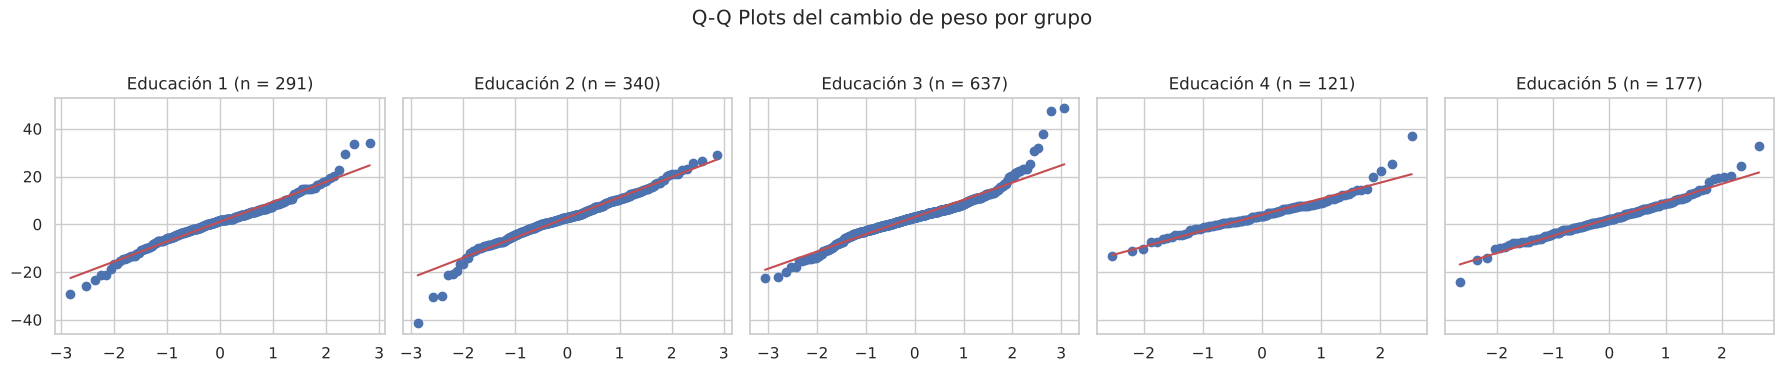

In [8]:
grupos = {k: g[OUTCOME_CAUSAL].values for k, g in dc.groupby("education")}
diag = pd.DataFrame({k: {"n": len(v), "media": v.mean(), "desvío": v.std(ddof=1), "asimetría": stats.skew(v),
                         "curtosis (exceso)": stats.kurtosis(v), "Shapiro p": stats.shapiro(v).pvalue}
                     for k, v in grupos.items()}).T
diag.index.name = "educación"
display(diag.style.format({"n": "{:.0f}", "Shapiro p": "{:.2e}"}, precision=3))
lev = stats.levene(*grupos.values(), center="median")
print(f"Levene (Brown-Forsythe): W = {lev.statistic:.3f}, p = {lev.pvalue:.4f}  |  cociente var. máx/mín = {diag['desvío'].max()**2 / diag['desvío'].min()**2:.2f}")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for ax, (k, v) in zip(axes, grupos.items()):
    stats.probplot(v, dist="norm", plot=ax); ax.set_title(f"Educación {k} (n = {len(v)})"); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Q-Q Plots del cambio de peso por grupo", y=1.03); plt.tight_layout(); plt.show()

In [9]:
f_clas = stats.f_oneway(*grupos.values())
welch = anova_oneway(dc[OUTCOME_CAUSAL], dc["education"], use_var="unequal", welch_correction=True)
kw = stats.kruskal(*grupos.values())
ss_between = sum(len(v) * (v.mean() - dc[OUTCOME_CAUSAL].mean()) ** 2 for v in grupos.values())
eta2 = ss_between / ((dc[OUTCOME_CAUSAL] - dc[OUTCOME_CAUSAL].mean()) ** 2).sum()
anova_tab = pd.DataFrame({
    "Estadístico": [f_clas.statistic, welch.statistic, kw.statistic],
    "gl": [f"{len(grupos)-1}, {len(dc)-len(grupos)}", f"{welch.df[0]:.0f}, {welch.df[1]:.1f}", f"{len(grupos)-1}"],
    "p-valor": [f_clas.pvalue, welch.pvalue, kw.pvalue],
    "Supuesto de varianzas": ["Iguales", "Distintas (robusto)", "No paramétrico"],
}, index=["ANOVA clásico (F)", "Welch ANOVA", "Kruskal-Wallis (H)"])
display(anova_tab.style.format({"Estadístico": "{:.3f}", "p-valor": "{:.4f}"}))
print(f"η² (proporción de la varianza explicada por la educación) = {eta2:.4f}")

,Estadístico,gl,p-valor,Supuesto de varianzas
ANOVA clásico (F),4.331,"4, 1561",0.0017,Iguales
Welch ANOVA,4.205,"4, 498.8",0.0023,Distintas (robusto)
Kruskal-Wallis (H),20.016,4,0.0005,No paramétrico


η² (proporción de la varianza explicada por la educación) = 0.0110


In [10]:
tukey = pairwise_tukeyhsd(dc[OUTCOME_CAUSAL], dc["education"], alpha=ALPHA)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0]).rename(columns={"p-adj": "p Tukey"})
pares = []
for (a, b) in [(int(r.group1), int(r.group2)) for r in tk.itertuples()]:
    t_ = stats.ttest_ind(grupos[a], grupos[b], equal_var=False)
    pares.append(min(t_.pvalue * len(tk), 1.0))
tk["p Bonferroni (Welch)"] = pares
tk["Difieren (Tukey)"] = tk["reject"].map({True: "Sí", False: "No"})
tk["Difieren (Bonferroni)"] = np.where(tk["p Bonferroni (Welch)"] < ALPHA, "Sí", "No")
tk.drop(columns="reject").style.format({"meandiff": "{:.3f}", "p Tukey": "{:.4f}", "lower": "{:.3f}", "upper": "{:.3f}", "p Bonferroni (Welch)": "{:.4f}"}).hide(axis="index")

group1,group2,meandiff,p Tukey,lower,upper,p Bonferroni (Welch),Difieren (Tukey),Difieren (Bonferroni)
1,2,1.780,0.0367,0.069,3.492,0.0901,Sí,No
1,3,1.949,0.0042,0.433,3.465,0.0079,Sí,Sí
1,4,2.961,0.0045,0.643,5.279,0.0025,Sí,Sí
1,5,1.346,0.3743,-0.697,3.388,0.6956,No,No
2,3,0.169,0.9977,-1.271,1.608,1.0000,No,No
2,4,1.181,0.6136,-1.087,3.449,1.0000,No,No
2,5,-0.434,0.9755,-2.421,1.552,1.0000,No,No
3,4,1.012,0.6905,-1.113,3.138,1.0000,No,No
3,5,-0.603,0.8953,-2.424,1.218,1.0000,No,No
4,5,-1.616,0.4063,-4.143,0.912,0.5315,No,No


### 1.4 · Interpretación


- **Normalidad:** Shapiro-Wilk rechaza en los 5 grupos (p entre 10⁻³ y 10⁻¹⁶). Con 121 a 637 observaciones por grupo, el test detecta desvíos mínimos. El criterio relevante para el TCL se cumple: **la asimetría está en [−1; 1]** en 4 de 5 grupos (el grupo 4 tiene 1,05, en el límite) y los Q-Q Plots son lineales en el centro. Lo que sí hay son **colas pesadas** (curtosis en exceso de 2,2 a 5,5).
- **Homocedasticidad:** Levene rechaza (W = 3,12; **p = 0,014**), aunque la razón entre varianzas extremas es moderada (1,55).
- **Elección del test:** por la heterocedasticidad demostrada, el contraste principal es el **ANOVA de Welch**: F = 4,21 con (4; 498,8) gl, **p = 0,0023**. Kruskal-Wallis, robusto también a las colas pesadas, coincide (H = 20,0; p = 0,0005). El ANOVA clásico da casi lo mismo (p = 0,0017). **Se rechaza $H_0$**: el aumento de peso medio difiere según el nivel educativo.
- **Magnitud:** η² = 0,011. La educación explica apenas el **1,1%** de la variabilidad: la diferencia es estadísticamente significativa, pero chica en la práctica.
- **Post-hoc:** Tukey HSD (que supone varianzas iguales) encuentra que el grupo 1 (≤ 8.º grado, +1,1 kg) difiere de los grupos 2, 3 y 4. **Bonferroni sobre t de Welch**, más conservador y válido con varianzas distintas, confirma solo 1 vs. 3 (p = 0,008) y 1 vs. 4 (p = 0,003); 1 vs. 2 deja de ser significativo (p = 0,09). Con heterocedasticidad, se prefiere la segunda.
- **Advertencia:** el grupo de menor educación es también el de **mayor edad**, y la edad reduce el aumento de peso. Este ANOVA describe diferencias entre grupos, pero no prueba que la educación cause un menor aumento de peso.

<a id="fase2"></a>
---
# FASE 2 — Diagnóstico de Gauss-Markov, puntos influyentes, VIF y PCA

## 2.1 Modelo lineal de referencia (MCO)

$$\Delta peso_i = \beta_0 + \beta_1\,qsmk_i + \sum_k \beta_k\, X_{ik} + \varepsilon_i$$

con las covariables basales de 1971. Es un modelo **descriptivo/predictivo** de referencia; el efecto causal se trata en la Fase 4.

In [11]:
FORM_MCO = (f"{OUTCOME_CAUSAL} ~ qsmk + sex + race + age + smokeyrs + smokeintensity + wt71 + ht + school + C(education)"
            " + income + C(exercise) + C(active) + cholesterol + alcoholfreq")
d2 = dc.dropna(subset=["income", "cholesterol", "alcoholfreq"]).reset_index(drop=True)
mco = smf.ols(FORM_MCO, data=d2).fit()
print(f"n = {int(mco.nobs)} | R² = {mco.rsquared:.4f} | R² ajustado = {mco.rsquared_adj:.4f} | "
      f"F = {mco.fvalue:.2f} (p = {mco.f_pvalue:.2e}) | RMSE = {np.sqrt(mco.mse_resid):.3f} kg")
coefs = pd.DataFrame({"β̂": mco.params, "EE": mco.bse, "t": mco.tvalues, "p-valor": mco.pvalues})
coefs.style.format({"β̂": "{:.4f}", "EE": "{:.4f}", "t": "{:.2f}", "p-valor": "{:.4f}"})

n = 1487 | R² = 0.1261 | R² ajustado = 0.1142 | F = 10.58 (p = 1.92e-31) | RMSE = 7.369 kg


,β̂,EE,t,p-valor
Intercept,1.2355,5.8692,0.21,0.8333
C(education)[T.2],-0.5120,0.9076,-0.56,0.5728
C(education)[T.3],-1.7055,1.1605,-1.47,0.1419
C(education)[T.4],-1.7997,1.5537,-1.16,0.2469
C(education)[T.5],-4.6271,1.9867,-2.33,0.0200
C(exercise)[T.1],0.2261,0.5492,0.41,0.6807
C(exercise)[T.2],0.2312,0.5758,0.40,0.6881
C(active)[T.1],-0.8793,0.4231,-2.08,0.0379
C(active)[T.2],0.3499,0.7207,0.49,0.6274
qsmk,3.2075,0.4518,7.10,0.0000


## 2.2 Auditoría de los supuestos de Gauss-Markov

,Estadístico,p-valor,Lectura
Breusch-Pagan,81.450,0.0000,H0: homocedasticidad
Jarque-Bera,1103.781,0.0000,H0: residuos normales
Durbin-Watson,2.009,—,≈ 2 → sin autocorrelación (orden por seqn)


Residuos: asimetría 0.524, curtosis (exceso) 4.089


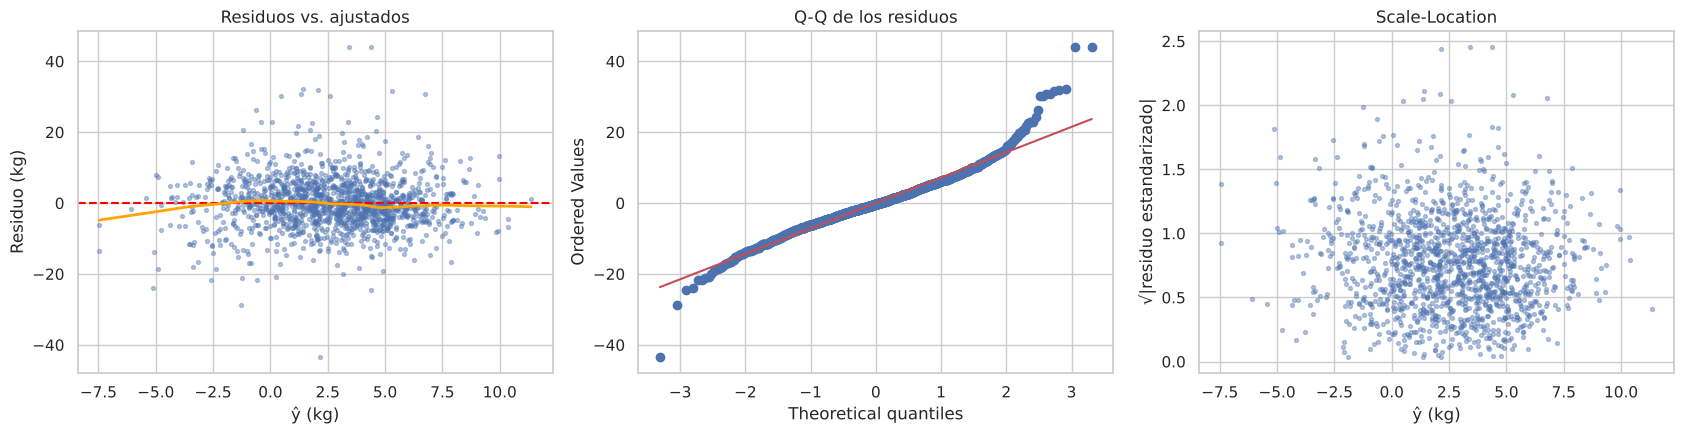

EE de qsmk: clásico 0.4518 vs. robusto HC3 0.4946


In [12]:
res = mco.resid
bp = het_breuschpagan(res, mco.model.exog)
jb = jarque_bera(res)
dw = durbin_watson(res)
sup = pd.DataFrame({
    "Estadístico": [bp[0], jb[0], dw],
    "p-valor": [bp[1], jb[1], np.nan],
    "Lectura": ["H0: homocedasticidad", "H0: residuos normales", "≈ 2 → sin autocorrelación (orden por seqn)"],
}, index=["Breusch-Pagan", "Jarque-Bera", "Durbin-Watson"])
display(sup.style.format({"Estadístico": "{:.3f}", "p-valor": "{:.4f}"}, na_rep="—"))
print(f"Residuos: asimetría {stats.skew(res):.3f}, curtosis (exceso) {stats.kurtosis(res):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(mco.fittedvalues, res, s=8, alpha=0.4); axes[0].axhline(0, color="red", ls="--")
lw = sm.nonparametric.lowess(res, mco.fittedvalues, frac=0.3); axes[0].plot(lw[:, 0], lw[:, 1], color="orange", lw=2)
axes[0].set_xlabel("ŷ (kg)"); axes[0].set_ylabel("Residuo (kg)"); axes[0].set_title("Residuos vs. ajustados")
stats.probplot(res, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q de los residuos")
axes[2].scatter(mco.fittedvalues, np.sqrt(np.abs(mco.get_influence().resid_studentized_internal)), s=8, alpha=0.4)
axes[2].set_xlabel("ŷ (kg)"); axes[2].set_ylabel("√|residuo estandarizado|"); axes[2].set_title("Scale-Location")
plt.tight_layout(); plt.show()

hc3 = mco.get_robustcov_results(cov_type="HC3")
print(f"EE de qsmk: clásico {mco.bse['qsmk']:.4f} vs. robusto HC3 {hc3.bse[list(mco.params.index).index('qsmk')]:.4f}")

## 2.3 Observaciones extremas: *outliers*, *leverage* y distancia de Cook

$$D_i = \frac{e_i^2}{(p+1)\,MSE}\left[\frac{h_{ii}}{(1-h_{ii})^2}\right]$$

|r| > 3                  19
h > 2(p+1)/n = 0.0282    33
Cook > 4/n = 0.0027      76
Cook > 0,5                0


seqn,Δpeso,qsmk,wt71,r_estud,h,Cook
23321,-41.28,0,93.0,-6.02,0.0176,0.0301
23522,48.54,0,71.2,6.12,0.0166,0.0294
5464,33.68,0,57.5,4.47,0.0290,0.0281
6928,47.51,1,89.0,6.09,0.0120,0.0209
24363,-30.05,0,105.8,-3.97,0.0241,0.0184
5415,34.02,0,73.0,4.40,0.0194,0.0181
17408,30.62,0,96.8,4.16,0.0200,0.0166
5412,-29.03,0,135.6,-3.30,0.0282,0.0149


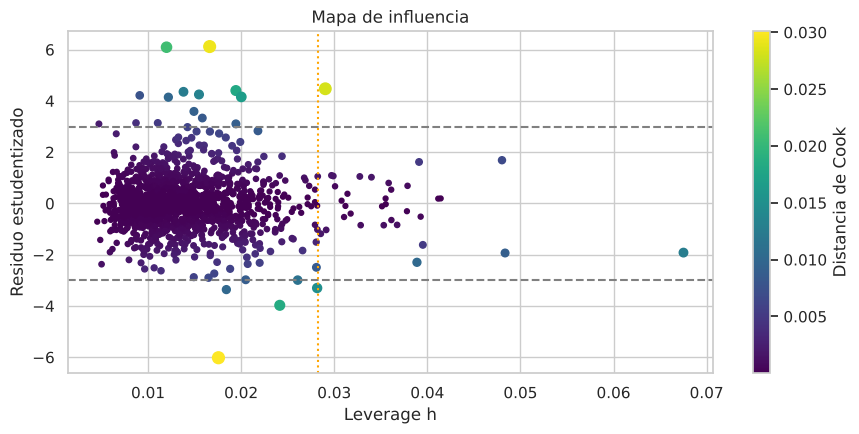

,MCO,Huber (RLM),diferencia %
qsmk,3.207480,2.807256,-12.5%
age,-0.208297,-0.163431,+21.5%
smokeintensity,0.020446,0.013988,-31.6%
wt71,-0.103655,-0.092360,+10.9%
ht,0.064393,0.042067,-34.7%


In [13]:
inf = OLSInfluence(mco)
n, p1 = int(mco.nobs), int(mco.df_model) + 1
diag_inf = pd.DataFrame({"seqn": d2["seqn"], "Δpeso": d2[OUTCOME_CAUSAL], "qsmk": d2["qsmk"], "wt71": d2["wt71"],
                         "r_estud": inf.resid_studentized_external, "h": inf.hat_matrix_diag, "Cook": inf.cooks_distance[0]})
umb = {"|r| > 3": (diag_inf["r_estud"].abs() > 3).sum(), f"h > 2(p+1)/n = {2*p1/n:.4f}": (diag_inf["h"] > 2 * p1 / n).sum(),
       f"Cook > 4/n = {4/n:.4f}": (diag_inf["Cook"] > 4 / n).sum(), "Cook > 0,5": (diag_inf["Cook"] > 0.5).sum()}
print(pd.Series(umb).to_string())
display(diag_inf.sort_values("Cook", ascending=False).head(8).style.format({"Δpeso": "{:.2f}", "wt71": "{:.1f}", "r_estud": "{:.2f}", "h": "{:.4f}", "Cook": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.5))
sc = ax.scatter(diag_inf["h"], diag_inf["r_estud"], c=diag_inf["Cook"], cmap="viridis", s=12 + 2000 * diag_inf["Cook"])
ax.axhline(3, color="gray", ls="--"); ax.axhline(-3, color="gray", ls="--"); ax.axvline(2 * p1 / n, color="orange", ls=":")
plt.colorbar(sc, label="Distancia de Cook"); ax.set_xlabel("Leverage h"); ax.set_ylabel("Residuo estudentizado")
ax.set_title("Mapa de influencia"); plt.tight_layout(); plt.show()

huber = smf.rlm(FORM_MCO, data=d2, M=sm.robust.norms.HuberT()).fit()
comp_rob = pd.DataFrame({"MCO": mco.params, "Huber (RLM)": huber.params}).loc[["qsmk", "age", "smokeintensity", "wt71", "ht"]]
comp_rob["diferencia %"] = 100 * (comp_rob["Huber (RLM)"] - comp_rob["MCO"]) / comp_rob["MCO"].abs()
display(comp_rob.style.format("{:.4f}").format({"diferencia %": "{:+.1f}%"}))

### 2.2–2.3 · Interpretación


- **Ajuste:** R² = 0,126 (ajustado 0,114); F = 10,6, p ≈ 2 × 10⁻³¹. El cambio de peso a 11 años es muy variable entre personas (RMSE ≈ 7,4 kg), y las covariables basales explican poco. Dejar de fumar se asocia con **+3,21 kg** (t = 7,1), cada año de edad con −0,21 kg y cada kg de peso inicial con −0,10 kg (los más pesados ganan menos: regresión a la media).
- **Homocedasticidad:** Breusch-Pagan **rechaza** (LM = 81,5; p < 0,001). Para la inferencia se usan errores robustos **HC3**: el EE de `qsmk` pasa de 0,45 a 0,49, y el coeficiente sigue siendo claramente significativo.
- **Normalidad:** Jarque-Bera rechaza (JB = 1.104). Los residuos tienen asimetría 0,52 y **curtosis en exceso de 4,1** (colas pesadas). Con n = 1.487, la inferencia sobre los coeficientes sigue siendo válida por el TCL, pero los intervalos de **predicción** individuales gaussianos serían demasiado angostos.
- **Independencia:** Durbin-Watson = 2,01. No hay autocorrelación según el orden de `seqn`; los datos son de corte transversal.
- **Observaciones extremas:** 19 *outliers* (|r| > 3), 33 puntos de alto *leverage* y 76 con Cook > 4/n, pero **ninguno con Cook > 0,5** (máximo 0,03). Los casos más extremos (−41 y +49 kg en 11 años) son plausibles en una cohorte de adultos (enfermedad grave, obesidad), así que **no se eliminan**. Como sensibilidad, una **regresión robusta de Huber** reduce el coeficiente de `qsmk` de 3,21 a 2,81 (−12,5%): las colas pesadas lo inflan un poco, pero el signo, la magnitud y la significancia se mantienen.

## 2.4 Multicolinealidad (VIF)

In [14]:
def vif_tabla(datos, cols):
    X = sm.add_constant(datos[cols].astype(float)).values
    return pd.Series([variance_inflation_factor(X, i + 1) for i in range(len(cols))], index=cols)

cols_vif = ["qsmk", "sex", "race", "age", "smokeyrs", "smokeintensity", "wt71", "ht", "school", "education", "income", "exercise", "active", "cholesterol", "alcoholfreq"]
cols_vif2 = [c for c in cols_vif if c not in ("school", "smokeyrs")] + ["edad_inicio"]
vif = pd.concat([vif_tabla(d2, cols_vif).rename("VIF original"), vif_tabla(d2, cols_vif2).rename("VIF tras la resolución")], axis=1)
display(vif.sort_values("VIF original", ascending=False).style.format("{:.2f}", na_rep="—"))
print(f"corr(age, smokeyrs) = {d2[['age','smokeyrs']].corr().iloc[0,1]:.3f}  |  corr(age, edad_inicio) = {d2[['age','edad_inicio']].corr().iloc[0,1]:.3f}"
      f"  |  corr(school, education) = {d2[['school','education']].corr(method='spearman').iloc[0,1]:.3f}")

,VIF original,VIF tras la resolución
school,7.72,—
education,7.48,1.40
smokeyrs,4.70,—
age,4.66,1.36
ht,2.37,2.37
sex,2.37,2.35
wt71,1.44,1.44
income,1.37,1.35
race,1.17,1.17
exercise,1.17,1.17


corr(age, smokeyrs) = 0.868  |  corr(age, edad_inicio) = 0.253  |  corr(school, education) = 0.992


### 2.4 · Resolución


- **`school` / `education` (VIF ≈ 7,7 / 7,5; Spearman = 0,99):** miden el mismo constructo, uno en años y el otro en categorías. **Se elimina `school`** y se conserva `education` como categórica, que captura efectos no lineales.
- **`age` / `smokeyrs` (VIF ≈ 4,7; r = 0,87):** cuanto mayor es la persona, más años lleva fumando. En lugar de eliminar una, se usa una **combinación funcional**: `edad_inicio = age − smokeyrs` (edad a la que empezó a fumar), con una correlación de solo 0,25 con la edad. Después de la resolución, **todos los VIF son < 2,4**.
- **Para la estimación causal** (Fase 4), `age` y `smokeyrs` se mantienen ambas porque son confusores distintos del DAG. La colinealidad afecta la precisión de sus propios coeficientes, no la del coeficiente del tratamiento. En la Fase 3, la regularización **Ridge/L2** absorbe la colinealidad que queda.

## 2.5 PCA sin *data leakage*

Regla estricta: la estandarización y la descomposición se ajustan **solo con el conjunto de entrenamiento** (el mismo de la Fase 3) y la matriz de rotación se aplica "a ciegas" sobre test.

,autovalor λ,% varianza,% acumulado
PC1,2.289,28.586,28.586
PC2,1.612,20.133,48.719
PC3,1.203,15.029,63.748
PC4,0.955,11.932,75.680
PC5,0.815,10.176,85.856
PC6,0.550,6.873,92.729
PC7,0.471,5.880,98.609
PC8,0.111,1.391,100.000


Criterio de Kaiser (λ > 1): 3 componentes (63.7% de la varianza)
Control anti-leakage: medias del escalador = medias de TRAIN → True


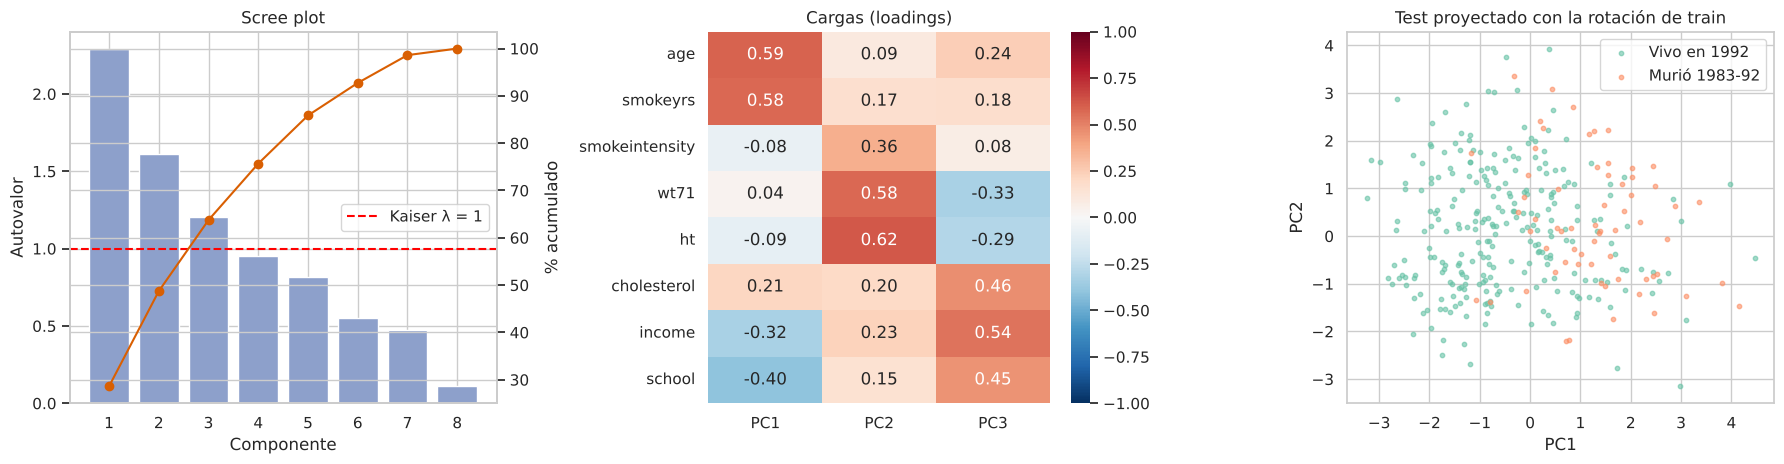

In [15]:
Xtr, Xte, ytr, yte = features.split(d)
med_tr = d.loc[Xtr.index, PCA_VARS].median()
P_tr = d.loc[Xtr.index, PCA_VARS].fillna(med_tr)
P_te = d.loc[Xte.index, PCA_VARS].fillna(med_tr)          # imputación con la mediana de TRAIN
pca_pipe = pipeline.fit_pca(P_tr)
pca = pca_pipe.named_steps["pca"]
tabla_pca = pd.DataFrame({"autovalor λ": pca.explained_variance_, "% varianza": 100 * pca.explained_variance_ratio_,
                          "% acumulado": 100 * np.cumsum(pca.explained_variance_ratio_)}, index=[f"PC{i+1}" for i in range(len(PCA_VARS))])
display(tabla_pca.style.format("{:.3f}"))
k_kaiser = int((pca.explained_variance_ > 1).sum())
print(f"Criterio de Kaiser (λ > 1): {k_kaiser} componentes ({tabla_pca['% acumulado'].iloc[k_kaiser-1]:.1f}% de la varianza)")
print(f"Control anti-leakage: medias del escalador = medias de TRAIN → {np.allclose(pca_pipe.named_steps['escalar'].mean_, P_tr.mean())}")

Z_te = pca_pipe.transform(P_te)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
pcs = np.arange(1, len(PCA_VARS) + 1)
axes[0].bar(pcs, pca.explained_variance_, color="#8da0cb"); axes[0].axhline(1, color="red", ls="--", label="Kaiser λ = 1")
ax2 = axes[0].twinx(); ax2.plot(pcs, 100 * np.cumsum(pca.explained_variance_ratio_), "o-", color="#d95f02"); ax2.set_ylabel("% acumulado")
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("Autovalor"); axes[0].set_title("Scree plot"); axes[0].legend(loc="center right")
cargas = pd.DataFrame(pca.components_[:3].T, index=PCA_VARS, columns=["PC1", "PC2", "PC3"])
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Cargas (loadings)")
for k, col in [(0, "#66c2a5"), (1, "#fc8d62")]:
    m = yte.values == k
    axes[2].scatter(Z_te[m, 0], Z_te[m, 1], s=10, alpha=0.6, color=col, label="Murió 1983-92" if k else "Vivo en 1992")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].set_title("Test proyectado con la rotación de train"); axes[2].legend()
plt.tight_layout(); plt.show()

### 2.5 · Interpretación de las componentes


- **Cantidad de componentes:** por Kaiser se retienen **3 componentes** (λ = 2,29; 1,61; 1,20), que explican el **63,7%** de la varianza. El codo del *scree plot* está en PC3–PC4, y para superar el 85% harían falta 5.
- **PC1 (28,6%) — "envejecimiento y exposición acumulada en contexto socioeconómico bajo":** cargas positivas en edad (+0,59) y años fumando (+0,58), negativas en escolaridad (−0,40) e ingreso (−0,32).
- **PC2 (20,1%) — "tamaño corporal e intensidad de consumo":** altura (+0,62), peso (+0,58) y cigarrillos/día (+0,36).
- **PC3 (15,0%) — "nivel socioeconómico y colesterol"**, con cargas positivas en ingreso, escolaridad y colesterol.
- En la proyección del test (con la rotación aprendida en train), los fallecidos se concentran en **valores altos de PC1**: el eje de envejecimiento y exposición es el que ordena el riesgo de muerte, lo que anticipa la Fase 3.
- El control anti-*leakage* confirma que las medias del escalador son exactamente las de train.

<a id="fase3"></a>
---
# FASE 3 — Torneo de modelos predictivos, calibración y explicabilidad

**Pregunta predictiva:** con la información disponible en 1971 (y si la persona dejó de fumar), ¿cuál es la probabilidad de morir entre 1983 y 1992? Es un problema de **clasificación binaria** con prevalencia ≈ 19,5%. Partición 80/20 **estratificada** y `StratifiedKFold(5)` en train; todas las transformaciones viven dentro de `Pipeline` (sin *leakage*).

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_recall_fscore_support,
                             roc_curve, precision_recall_curve, f1_score, accuracy_score)

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(f"Train: {len(Xtr)} ({ytr.mean():.2%} muertes) | Test: {len(Xte)} ({yte.mean():.2%} muertes) | predictoras: {Xtr.shape[1]}")
modelos = {}

Train: 1303 (19.49% muertes) | Test: 326 (19.63% muertes) | predictoras: 37


### Familia 1 — Regresión logística: Odds Ratios (statsmodels) y versión regularizada (scikit-learn)

In [17]:
FORM_LOGIT = "death ~ age + sex + race + C(education) + smokeintensity + smokeyrs + wt71 + C(exercise) + C(active) + qsmk + hf + tumor + bronch + C(hbp_cat)"
logit_sm = smf.logit(FORM_LOGIT, data=d.loc[Xtr.index]).fit(disp=0)
or_tab = pd.DataFrame({"β̂": logit_sm.params, "OR": np.exp(logit_sm.params), "IC95 inf": np.exp(logit_sm.conf_int()[0]),
                       "IC95 sup": np.exp(logit_sm.conf_int()[1]), "p-valor": logit_sm.pvalues}).drop(index="Intercept")
print(f"Pseudo R² McFadden = {logit_sm.prsquared:.4f} | LLR p = {logit_sm.llr_pvalue:.2e}")
display(or_tab.style.format({"β̂": "{:.4f}", "OR": "{:.3f}", "IC95 inf": "{:.3f}", "IC95 sup": "{:.3f}", "p-valor": "{:.4f}"}))

gs_lr = GridSearchCV(features.make_pipeline(pipeline.logit_base()), pipeline.LOGIT_GRID, cv=skf, scoring="neg_brier_score").fit(Xtr, ytr)
modelos["Logística regularizada"] = gs_lr.best_estimator_
print("Mejores hiperparámetros (CV, Brier):", gs_lr.best_params_)

Pseudo R² McFadden = 0.2816 | LLR p = 1.48e-64


,β̂,OR,IC95 inf,IC95 sup,p-valor
C(education)[T.2],-0.1600,0.852,0.540,1.345,0.4918
C(education)[T.3],-0.6703,0.512,0.331,0.790,0.0025
C(education)[T.4],0.0006,1.001,0.471,2.125,0.9988
C(education)[T.5],-0.5025,0.605,0.316,1.158,0.1291
C(exercise)[T.1],-0.1635,0.849,0.512,1.410,0.5272
C(exercise)[T.2],0.1321,1.141,0.687,1.895,0.6095
C(active)[T.1],0.3878,1.474,1.023,2.122,0.0372
C(active)[T.2],0.5193,1.681,0.966,2.925,0.0662
C(hbp_cat)[T.no_informado],-0.3251,0.722,0.503,1.037,0.0780
C(hbp_cat)[T.si],0.4192,1.521,0.889,2.603,0.1263


Mejores hiperparámetros (CV, Brier): {'modelo__C': 0.03, 'modelo__l1_ratio': 0.0}


### Familia 2 — Gaussian Naive Bayes

In [18]:
modelos["Gaussian Naive Bayes"] = features.make_pipeline(GaussianNB()).fit(Xtr, ytr)
corr_cond = Xtr[ytr == 0][["age", "smokeyrs", "wt71", "ht"]].corr()
print("Correlaciones DENTRO de la clase 'vivo' (el supuesto de NB exige ≈ 0):")
print(corr_cond.round(2).to_string())

Correlaciones DENTRO de la clase 'vivo' (el supuesto de NB exige ≈ 0):
             age  smokeyrs   wt71      ht
age       1.0000    0.8600 0.0400 -0.0900
smokeyrs  0.8600    1.0000 0.0900  0.0200
wt71      0.0400    0.0900 1.0000  0.4900
ht       -0.0900    0.0200 0.4900  1.0000


### Familia 3 — Árbol CART: sobreajuste y poda por costo-complejidad

Árbol sin restricciones: 180 hojas | AUC train = 1.000 | AUC test = 0.621 | accuracy train = 1.000, test = 0.770


α óptimo (CV) = 0.00310 → 7 hojas, profundidad 4


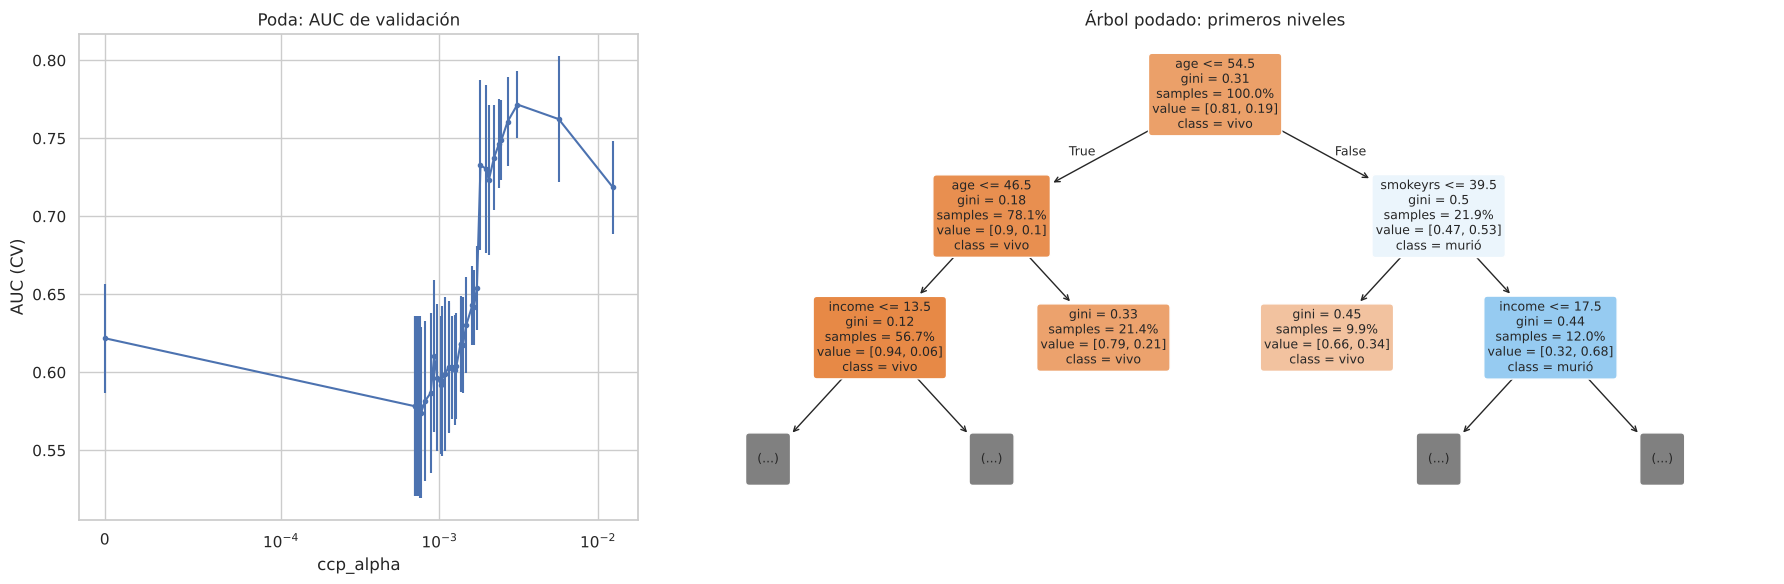

In [19]:
arbol_full = features.make_pipeline(DecisionTreeClassifier(random_state=SEED), scale=False).fit(Xtr, ytr)
print(f"Árbol sin restricciones: {arbol_full[-1].get_n_leaves()} hojas | AUC train = {roc_auc_score(ytr, arbol_full.predict_proba(Xtr)[:, 1]):.3f} | "
      f"AUC test = {roc_auc_score(yte, arbol_full.predict_proba(Xte)[:, 1]):.3f} | accuracy train = {accuracy_score(ytr, arbol_full.predict(Xtr)):.3f}, test = {accuracy_score(yte, arbol_full.predict(Xte)):.3f}")

prep_tree = features.make_preprocessor(scale=False).fit(Xtr)
ruta = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(prep_tree.transform(Xtr), ytr)
alphas = np.unique(np.quantile(ruta.ccp_alphas[:-1], np.linspace(0, 1, 40)))
gs_tree = GridSearchCV(features.make_pipeline(DecisionTreeClassifier(random_state=SEED), scale=False),
                       {"modelo__ccp_alpha": alphas}, cv=skf, scoring="roc_auc").fit(Xtr, ytr)
modelos["Árbol CART podado"] = gs_tree.best_estimator_
arbol = gs_tree.best_estimator_[-1]
print(f"α óptimo (CV) = {gs_tree.best_params_['modelo__ccp_alpha']:.5f} → {arbol.get_n_leaves()} hojas, profundidad {arbol.get_depth()}")

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 2]})
cvr = pd.DataFrame(gs_tree.cv_results_)
axes[0].errorbar(cvr["param_modelo__ccp_alpha"].astype(float), cvr["mean_test_score"], yerr=cvr["std_test_score"], fmt="o-", ms=3)
axes[0].set_xscale("symlog", linthresh=1e-4); axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("AUC (CV)"); axes[0].set_title("Poda: AUC de validación")
plot_tree(arbol, max_depth=2, feature_names=list(gs_tree.best_estimator_[0].get_feature_names_out()), filled=True, rounded=True,
          class_names=["vivo", "murió"], proportion=True, precision=2, fontsize=9, ax=axes[1])
axes[1].set_title("Árbol podado: primeros niveles"); plt.tight_layout(); plt.show()

### Familia 4 — Random Forest: búsqueda de hiperparámetros y error OOB

Mejores hiperparámetros: {'modelo__n_estimators': 600, 'modelo__min_samples_split': 30, 'modelo__min_samples_leaf': 20, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 8}
AUC (CV 5-fold) = 0.8348  |  accuracy OOB = 0.8411


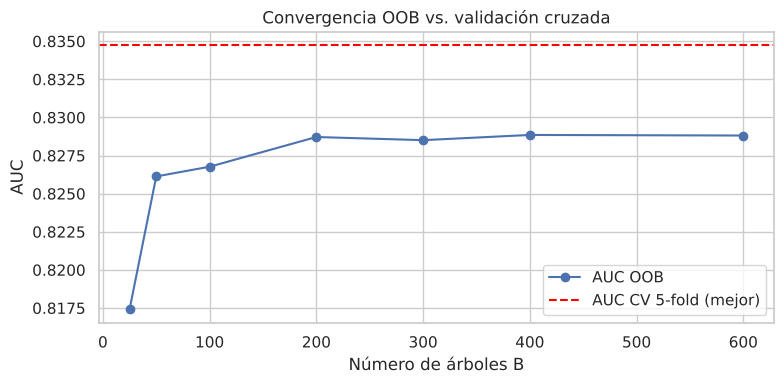

B          25     50     100    200    300    400    600
AUC OOB 0.8174 0.8261 0.8268 0.8287 0.8285 0.8289 0.8288


In [20]:
param_rf = {"modelo__n_estimators": [200, 400, 600], "modelo__max_depth": [3, 5, 8, 12, None],
            "modelo__min_samples_split": [2, 10, 30], "modelo__min_samples_leaf": [1, 5, 10, 20],
            "modelo__max_features": ["sqrt", "log2", 0.3, 0.5]}
rs_rf = RandomizedSearchCV(features.make_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=-1, oob_score=True), scale=False),
                           param_rf, n_iter=30, cv=skf, scoring="roc_auc", random_state=SEED).fit(Xtr, ytr)
modelos["Random Forest"] = rs_rf.best_estimator_
print("Mejores hiperparámetros:", rs_rf.best_params_)
print(f"AUC (CV 5-fold) = {rs_rf.best_score_:.4f}  |  accuracy OOB = {rs_rf.best_estimator_[-1].oob_score_:.4f}")

best_rf = {k.replace("modelo__", ""): v for k, v in rs_rf.best_params_.items() if k != "modelo__n_estimators"}
Xtr_t = rs_rf.best_estimator_[0].transform(Xtr)
oob = []
rf_ws = RandomForestClassifier(random_state=SEED, n_jobs=-1, oob_score=True, warm_start=True, **best_rf)
for B in [25, 50, 100, 200, 300, 400, 600]:
    rf_ws.set_params(n_estimators=B).fit(Xtr_t, ytr)
    oob.append({"B": B, "AUC OOB": roc_auc_score(ytr, rf_ws.oob_decision_function_[:, 1])})
oob = pd.DataFrame(oob)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(oob["B"], oob["AUC OOB"], "o-", label="AUC OOB"); ax.axhline(rs_rf.best_score_, color="red", ls="--", label="AUC CV 5-fold (mejor)")
ax.set_xlabel("Número de árboles B"); ax.set_ylabel("AUC"); ax.set_title("Convergencia OOB vs. validación cruzada"); ax.legend()
plt.tight_layout(); plt.show()
print(oob.set_index("B").T.round(4).to_string())

### Selección del modelo final por validación cruzada (no por test) y calibración

In [21]:
cv_sel = []
for nombre, m in modelos.items():
    p_cv = cross_val_predict(m, Xtr, ytr, cv=skf, method="predict_proba")[:, 1]
    cv_sel.append({"Modelo": nombre, "AUC CV": roc_auc_score(ytr, p_cv), "Brier CV": brier_score_loss(ytr, p_cv)})
cv_sel = pd.DataFrame(cv_sel).set_index("Modelo").sort_values("Brier CV")
display(cv_sel.style.format("{:.4f}"))

C_final, L1_final = gs_lr.best_params_["modelo__C"], gs_lr.best_params_["modelo__l1_ratio"]
modelos["Logística calibrada (final)"] = pipeline.final_predictive_model(Xtr, ytr, C=C_final, l1_ratio=L1_final)
modelos["RF calibrado (isotónica)"] = CalibratedClassifierCV(rs_rf.best_estimator_, method="isotonic", cv=5).fit(Xtr, ytr)
modelos["NB calibrado (isotónica)"] = CalibratedClassifierCV(features.make_pipeline(GaussianNB()), method="isotonic", cv=5).fit(Xtr, ytr)

,AUC CV,Brier CV
Modelo,,
Logística regularizada,0.8384,0.1125
Random Forest,0.8337,0.1180
Árbol CART podado,0.7759,0.1300
Gaussian Naive Bayes,0.7557,0.2016


### Evaluación en test

,AUC-ROC,PR-AUC,Brier,Precision macro,Recall macro,F1 macro,F1 ponderado
Logística regularizada,0.8464,0.5476,0.1175,0.7539,0.6097,0.6322,0.7953
Gaussian Naive Bayes,0.7609,0.4085,0.2301,0.6352,0.6664,0.6450,0.7614
Árbol CART podado,0.8122,0.4921,0.1228,0.7550,0.6431,0.6702,0.8115
Random Forest,0.8547,0.5739,0.1180,0.7465,0.5686,0.5751,0.7706
Logística calibrada (final),0.8473,0.5466,0.1171,0.7486,0.6156,0.6391,0.7978
RF calibrado (isotónica),0.8537,0.5662,0.1166,0.7949,0.6076,0.6310,0.7974
NB calibrado (isotónica),0.7701,0.4068,0.1393,0.6536,0.5689,0.5771,0.7638
Referencia: predecir la prevalencia,0.5000,0.1963,0.1578,—,—,—,—


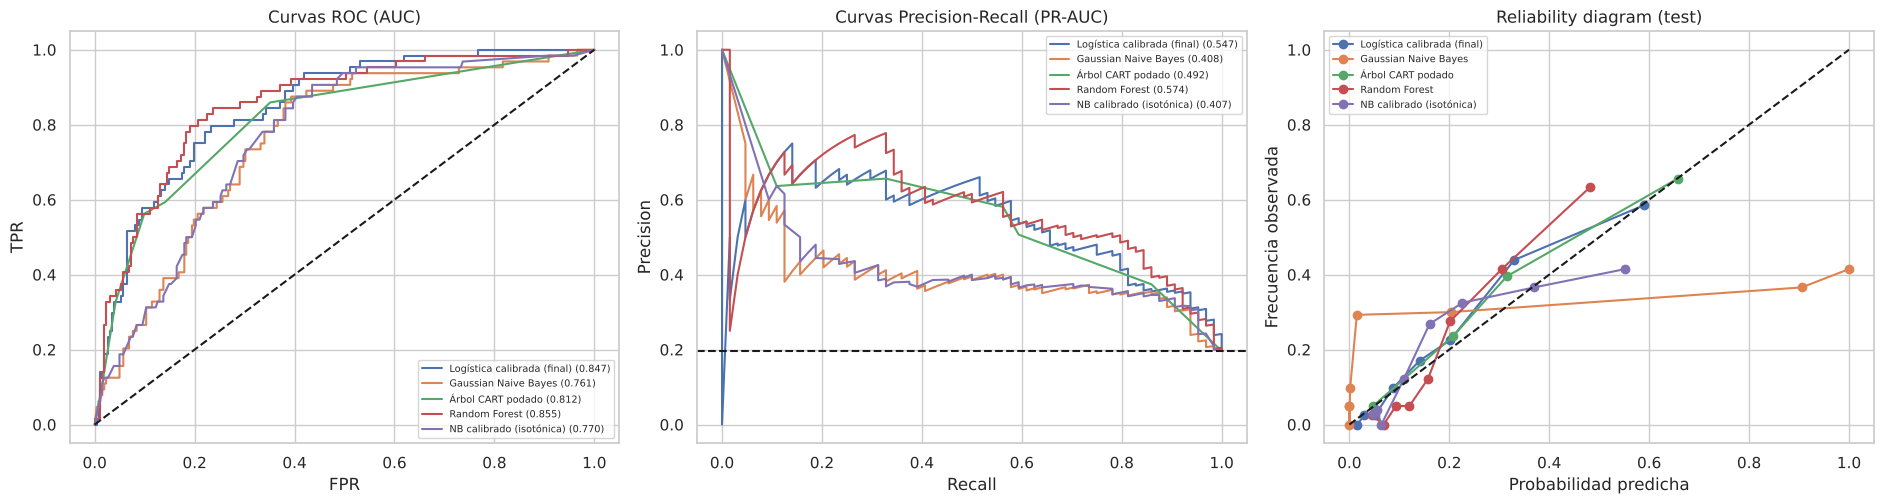

In [22]:
def eval_test(m, thr=0.5):
    p = m.predict_proba(Xte)[:, 1]; yhat = (p >= thr).astype(int)
    pm, rm, fm, _ = precision_recall_fscore_support(yte, yhat, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(yte, yhat, average="weighted", zero_division=0)
    return {"AUC-ROC": roc_auc_score(yte, p), "PR-AUC": average_precision_score(yte, p), "Brier": brier_score_loss(yte, p),
            "Precision macro": pm, "Recall macro": rm, "F1 macro": fm, "F1 ponderado": fw}

tabla_test = pd.DataFrame({k: eval_test(m) for k, m in modelos.items()}).T
tabla_test.loc["Referencia: predecir la prevalencia"] = {"AUC-ROC": 0.5, "PR-AUC": yte.mean(), "Brier": brier_score_loss(yte, np.full(len(yte), ytr.mean())),
                                                        "Precision macro": np.nan, "Recall macro": np.nan, "F1 macro": np.nan, "F1 ponderado": np.nan}
display(tabla_test.style.format("{:.4f}", na_rep="—"))

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
mostrar = ["Logística calibrada (final)", "Gaussian Naive Bayes", "Árbol CART podado", "Random Forest", "NB calibrado (isotónica)"]
for nombre in mostrar:
    p = modelos[nombre].predict_proba(Xte)[:, 1]
    f, t_, _ = roc_curve(yte, p); axes[0].plot(f, t_, label=f"{nombre} ({roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, label=f"{nombre} ({average_precision_score(yte, p):.3f})")
    fr, mp = calibration_curve(yte, p, n_bins=8, strategy="quantile"); axes[2].plot(mp, fr, "o-", label=nombre)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_title("Curvas ROC (AUC)"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[1].axhline(yte.mean(), color="k", ls="--"); axes[1].set_title("Curvas Precision-Recall (PR-AUC)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set_title("Reliability diagram (test)"); axes[2].set_xlabel("Probabilidad predicha"); axes[2].set_ylabel("Frecuencia observada")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Explicabilidad: MDI vs. importancia por permutación

,MDI (agregado por variable),Permutación ΔAUC (test),desvío,valores únicos
age,0.3037,0.0848,0.0224,49
smokeyrs,0.2877,0.0375,0.0170,60
income,0.0759,0.0114,0.0047,12
education,0.0716,0.0109,0.0068,5
cholesterol,0.0359,0.0049,0.0031,218
wt71,0.0292,-0.0001,0.0019,488
ht,0.0240,-0.0014,0.0014,358
hbp_cat,0.0211,0.0065,0.0034,3
exercise,0.0197,-0.0017,0.0016,3
sex,0.0194,-0.0002,0.0022,2


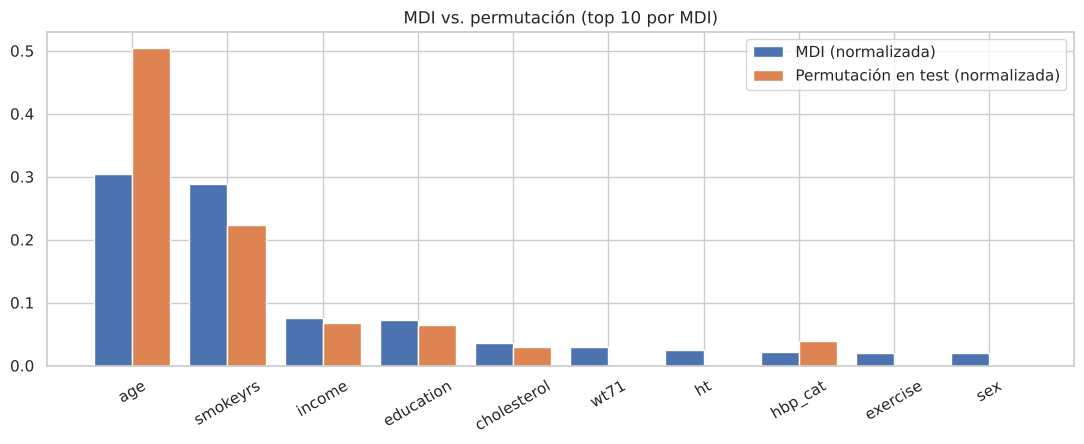

Control de sesgo de cardinalidad (variables de ruido puro):
                  MDI  Permutación ΔAUC
ruido_continuo 0.0245            0.0016
ruido_binario  0.0043            0.0001


In [23]:
rf_final = rs_rf.best_estimator_
nombres = list(rf_final[0].get_feature_names_out())
mdi = pd.Series(rf_final[-1].feature_importances_, index=nombres)
perm = permutation_importance(rf_final, Xte, yte, n_repeats=20, random_state=SEED, scoring="roc_auc", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=Xte.columns)
perm_sd = pd.Series(perm.importances_std, index=Xte.columns)
mdi_orig = pd.Series({c: mdi[[n for n in nombres if n == c or n.startswith(c + "_")]].sum() for c in Xte.columns})
imp = pd.DataFrame({"MDI (agregado por variable)": mdi_orig, "Permutación ΔAUC (test)": perm_s, "desvío": perm_sd,
                    "valores únicos": Xtr.nunique()}).sort_values("MDI (agregado por variable)", ascending=False)
display(imp.head(12).style.format({"MDI (agregado por variable)": "{:.4f}", "Permutación ΔAUC (test)": "{:.4f}", "desvío": "{:.4f}", "valores únicos": "{:.0f}"}))

top = imp.head(10).index
fig, ax = plt.subplots(figsize=(11, 4.6)); x = np.arange(len(top)); w = 0.4
ax.bar(x - w/2, imp.loc[top, "MDI (agregado por variable)"] / imp["MDI (agregado por variable)"].sum(), w, label="MDI (normalizada)")
ax.bar(x + w/2, imp.loc[top, "Permutación ΔAUC (test)"].clip(lower=0) / perm_s.clip(lower=0).sum(), w, label="Permutación en test (normalizada)")
ax.set_xticks(x); ax.set_xticklabels(top, rotation=30); ax.legend(); ax.set_title("MDI vs. permutación (top 10 por MDI)")
plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
Xr_tr = Xtr.assign(ruido_continuo=rng.normal(size=len(Xtr)), ruido_binario=rng.integers(0, 2, len(Xtr)))
Xr_te = Xte.assign(ruido_continuo=rng.normal(size=len(Xte)), ruido_binario=rng.integers(0, 2, len(Xte)))
prep_r = features.make_preprocessor(scale=False)
prep_r.transformers.append(("ruido", "passthrough", ["ruido_continuo", "ruido_binario"]))
rf_r = RandomForestClassifier(random_state=SEED, n_jobs=-1, n_estimators=400, **best_rf)
from sklearn.pipeline import Pipeline as _P
pipe_r = _P([("prep", prep_r), ("modelo", rf_r)]).fit(Xr_tr, ytr)
mdi_r = pd.Series(pipe_r[-1].feature_importances_, index=pipe_r[0].get_feature_names_out())
perm_r = permutation_importance(pipe_r, Xr_te, yte, n_repeats=20, random_state=SEED, scoring="roc_auc", n_jobs=-1)
perm_r = pd.Series(perm_r.importances_mean, index=Xr_te.columns)
print("Control de sesgo de cardinalidad (variables de ruido puro):")
print(pd.DataFrame({"MDI": mdi_r[["ruido_continuo", "ruido_binario"]], "Permutación ΔAUC": perm_r[["ruido_continuo", "ruido_binario"]]}).round(4).to_string())

### Fase 3 · Interpretación del torneo


**Selección del modelo (por CV, nunca por test).** La **logística regularizada** gana en CV en las dos métricas: AUC 0,838 y Brier 0,113. Le siguen el Random Forest (0,834 / 0,118), el árbol podado (0,776 / 0,130) y Naive Bayes (0,756 / 0,202). En test, el RF tiene un AUC levemente mayor (0,855 vs. 0,847), pero con solo 64 muertes en test esa diferencia está dentro del ruido. Se elige la logística calibrada por tres razones: mejor CV, mejor calibración y coeficientes interpretables. **Modelo final: logística L2 calibrada (sigmoide), AUC 0,847, PR-AUC 0,547, Brier 0,117** (la referencia de predecir la prevalencia da Brier 0,158).

**Odds Ratios (statsmodels, train):** cada año de edad multiplica las chances de morir en el período por **1,085** (≈ ×2,3 por década). Ser mujer las reduce (OR ≈ 0,62) y cada año adicional fumando las aumenta (OR ≈ 1,03). La hipertensión diagnosticada tiene un OR de ≈ 1,5, pero no es significativo (p = 0,13). Dejar de fumar **no** muestra un OR significativo (IC que incluye al 1). La interpretación causal de esto se discute en el ensayo.

**Naive Bayes y la violación de independencia:** dentro de la clase "vivo", edad y años fumando tienen una correlación de **0,86**, y peso y altura de 0,49. NB multiplica sus verosimilitudes como si fueran independientes y cuenta dos veces la misma evidencia. Por eso su Brier (0,230) es **peor que no usar modelo** (0,158), y en el *reliability diagram* sus probabilidades se pegan a 0 y a 1 (sobreconfianza). La calibración isotónica baja el Brier a 0,139, pero **no mejora el AUC** (0,77): calibrar arregla las probabilidades, no el orden de los casos.

**CART:** sin restricciones, el árbol memoriza el entrenamiento (180 hojas; AUC train 1,00 vs. test 0,62). La poda por costo-complejidad (α = 0,0031, elegido por CV) lo reduce a **7 hojas** y sube el AUC de test a 0,81. **Nodo raíz: edad ≤ 54,5 años.** En el subárbol de los mayores, el siguiente corte es haber fumado más de 39,5 años: ese grupo (12% de la muestra de entrenamiento) tiene una mortalidad observada del 68%.

**Random Forest:** la búsqueda aleatoria (30 combinaciones × 5 folds) eligió 600 árboles de profundidad 8, `min_samples_leaf = 20`, `min_samples_split = 30` y `max_features = 'sqrt'`: árboles bastante regularizados, coherente con una señal dominada por pocas variables. El AUC OOB se estabiliza a partir de ≈ 200 árboles y queda en el mismo nivel que el AUC de CV. El OOB es una alternativa válida a la CV en datos i.i.d. como estos (a diferencia de una serie temporal).

**MDI vs. permutación:** MDI pone a `smokeyrs` casi a la par de `age` (0,29 vs. 0,30), pero por permutación en test la edad es más del doble de importante (ΔAUC 0,085 vs. 0,038). `wt71` y `ht` (488 y 358 valores únicos) reciben MDI de 0,03 y 0,02 y **permutación ≈ 0 o negativa**. El **control con ruido puro** lo confirma: una variable continua aleatoria recibe **5,7 veces más MDI** que una binaria aleatoria (0,0245 vs. 0,0043), mientras que la permutación les asigna ≈ 0 a ambas.

La razón es que MDI acumula reducciones de impureza **en train**. Una variable con cientos de umbrales posibles encuentra, por azar, cortes que separan ruido en los nodos profundos; una binaria tiene un solo umbral. La permutación mide la caída de desempeño **en datos no vistos**, y el ajuste al ruido no generaliza, así que ese sesgo se neutraliza.

<a id="fase4"></a>
---
# FASE 4 — Inferencia causal: DAG, criterio *backdoor*, DoWhy, Double ML y refutaciones

**Pregunta causal:** si un programa de salud pública lograra que una persona fumadora deje de fumar — $do(qsmk = 1)$ —, ¿cuántos kilos ganaría en promedio en 11 años, comparado con seguir fumando? El aumento de peso es el principal efecto adverso que desalienta a dejar de fumar, y dimensionarlo permite planificar apoyo nutricional.

## 4.1 DAG estructural


| Arco(s) | Justificación de dominio |
|---|---|
| Z → T (sexo, raza, edad, educación, cigarrillos/día, años fumando, ejercicio, actividad, peso 1971) | Determinantes conocidos de la decisión de dejar de fumar: los más jóvenes, educados y livianos de consumo tienen más éxito; la preocupación por el peso influye en la decisión. |
| Z → Y | Los mismos factores afectan el cambio de peso: edad (metabolismo), sexo, peso inicial (regresión a la media), actividad física. |
| edad → años fumando; sexo, edad → peso 1971 | Relaciones entre confusores (años fumando depende de la edad; el peso depende de sexo y edad). |
| T → M → Y (M = ingesta calórica / metabolismo, **latente**) | Mecanismo biológico: la nicotina suprime el apetito y eleva el gasto energético; al dejar, aumentan la ingesta y la eficiencia metabólica. **No está medido.** |
| T → Y | Efecto total que se quiere estimar (incluye el paso por M). |
| precio del tabaco 82 → T | Candidato a **instrumento**: el precio incentiva dejar de fumar y no debería afectar el peso por otra vía. |
| T → C ← Y (C = presión sistólica 1982) | Dejar de fumar modifica la presión, y el aumento de peso la eleva: **colisionador post-tratamiento**. |
| U (conciencia de salud, **latente**) → T, ejercicio | **Amenaza a la validez:** personas más preocupadas por su salud dejan más y hacen más ejercicio. Si U también afectara al peso por vías no capturadas por Z, habría confusión no observada. |
| T, edad, peso 1971 → S (peso 1982 observado) | **Selección por censura:** analizar solo a los observados es condicionar en S. |

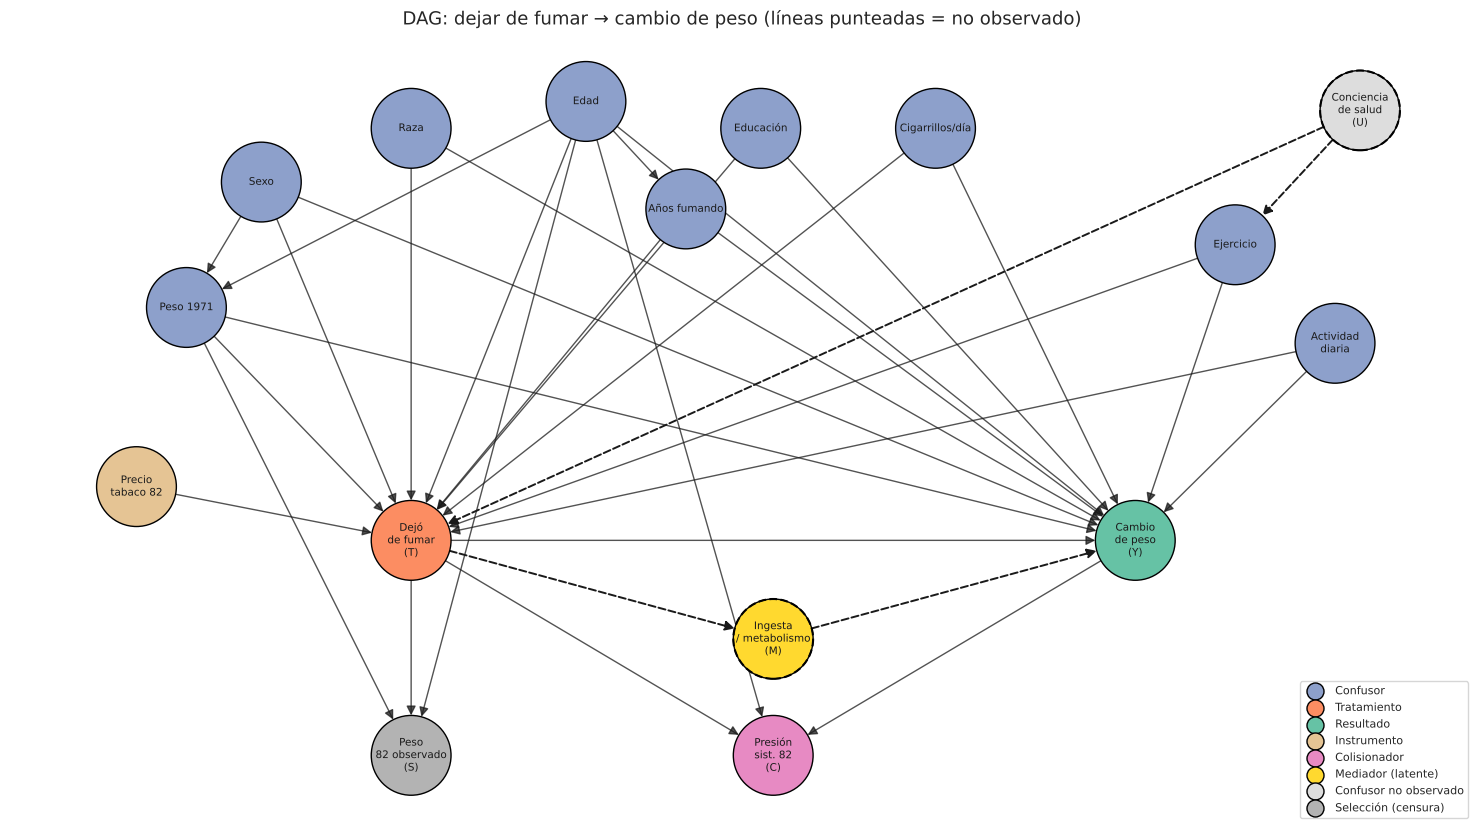

DOT (nodos observados, usado por DoWhy):
 digraph {sex -> qsmk; race -> qsmk; age -> qsmk; education -> qsmk; smokeintensity -> qsmk; smokeyrs -> qsmk; exercise -> qsmk; active -> qsmk; wt71 -> qsmk; sex -> wt82_71; race -> wt82_71; age -> wt82_71; education -> wt82_71; smokeintensity -> wt82_71; smokeyrs -> wt82_71; exercise -> wt82_71; active -> wt82_71; wt71 -> wt82_71; age -> smokeyrs; sex -> wt71; age -> wt71; price82 -> qsmk; qsmk -> wt82_71; qsmk -> sbp; wt82_71 -> sbp; age -> sbp;}


In [24]:
import networkx as nx
G_full = causal.graph(include_latent=True)
pos = {"sex": (0, 4), "race": (1.2, 4.6), "age": (2.6, 4.9), "education": (4.0, 4.6), "smokeintensity": (5.4, 4.6), "smokeyrs": (3.4, 3.7),
       "exercise": (7.8, 3.3), "active": (8.6, 2.2), "wt71": (-0.6, 2.6), "conciencia_salud": (8.8, 4.8),
       "price82": (-1.0, 0.6), TREATMENT: (1.2, 0.0), OUTCOME_CAUSAL: (7.0, 0.0), "ingesta_metabolismo": (4.1, -1.1),
       COLLIDER: (4.1, -2.4), "peso82_observado": (1.2, -2.4)}
COL = {"Confusor": "#8da0cb", "Tratamiento": "#fc8d62", "Resultado": "#66c2a5", "Instrumento": "#e5c494", "Colisionador": "#e78ac3",
       "Mediador (latente)": "#ffd92f", "Confusor no observado": "#dddddd", "Selección (censura)": "#b3b3b3"}
latentes = {"ingesta_metabolismo", "conciencia_salud"}
fig, ax = plt.subplots(figsize=(15, 8.5))
nx.draw_networkx_nodes(G_full, pos, node_color=[COL[causal.ROLES[n]] for n in G_full], node_size=3300, edgecolors="black", ax=ax)
for n in latentes:
    ax.scatter(*pos[n], s=3300, facecolors="none", edgecolors="black", linestyles="dashed", linewidths=1.5, zorder=3)
nx.draw_networkx_labels(G_full, pos, labels={n: causal.LABELS[n].replace(" (", "\n(").replace(" ", "\n", 1) if len(causal.LABELS[n]) > 12 else causal.LABELS[n] for n in G_full}, font_size=7.5, ax=ax)
lat_e = [e for e in G_full.edges if e[0] in latentes or e[1] in latentes]
nx.draw_networkx_edges(G_full, pos, edgelist=[e for e in G_full.edges if e not in lat_e], arrowsize=14, node_size=3300, width=1.0, alpha=0.75, ax=ax)
nx.draw_networkx_edges(G_full, pos, edgelist=lat_e, arrowsize=14, node_size=3300, width=1.4, style="dashed", ax=ax)
for rol, c in COL.items(): ax.scatter([], [], s=150, color=c, edgecolor="black", label=rol)
ax.legend(loc="lower right", fontsize=8); ax.set_axis_off(); ax.set_title("DAG: dejar de fumar → cambio de peso (líneas punteadas = no observado)", fontsize=13)
plt.tight_layout(); plt.show()
print("DOT (nodos observados, usado por DoWhy):\n", causal.dot())

## 4.2 Identificación: caminos y criterio *backdoor*

In [25]:
G = causal.graph()
caminos = causal.paths_table(G)
print(caminos["tipo"].value_counts().to_string(), "\n")
display(caminos.groupby("tipo").head(4).style.hide(axis="index"))
cands = CONFOUNDERS + [INSTRUMENT, COLLIDER]
minimos = causal.minimal_adjustment_sets(G, cands)
print("Conjuntos de ajuste mínimos válidos:", [sorted(s) for s in minimos])
pruebas = {"Z (9 confusores)": set(CONFOUNDERS), "Z sin wt71": set(CONFOUNDERS) - {"wt71"}, "Z sin smokeintensity": set(CONFOUNDERS) - {"smokeintensity"},
           "Z + colisionador sbp": set(CONFOUNDERS) | {COLLIDER}, "Z + instrumento price82": set(CONFOUNDERS) | {INSTRUMENT}, "∅ (ninguno)": set()}
pd.Series({k: causal.satisfies_backdoor(G, v) for k, v in pruebas.items()}, name="¿Cumple el criterio backdoor?").to_frame()

tipo
Puerta trasera (abierto)      17
Bloqueado por colisionador    13
Causal                         1 



camino,tipo,colisionadores,largo
qsmk → sbp ← wt82_71,Bloqueado por colisionador,sbp,2
qsmk → sbp ← age → wt82_71,Bloqueado por colisionador,sbp,3
qsmk ← age → sbp ← wt82_71,Bloqueado por colisionador,sbp,3
qsmk ← sex → wt71 ← age → wt82_71,Bloqueado por colisionador,wt71,4
qsmk → wt82_71,Causal,,1
qsmk ← sex → wt82_71,Puerta trasera (abierto),,2
qsmk ← race → wt82_71,Puerta trasera (abierto),,2
qsmk ← age → wt82_71,Puerta trasera (abierto),,2
qsmk ← education → wt82_71,Puerta trasera (abierto),,2


Conjuntos de ajuste mínimos válidos: [['active', 'age', 'education', 'exercise', 'race', 'sex', 'smokeintensity', 'smokeyrs', 'wt71']]


,¿Cumple el criterio backdoor?
Z (9 confusores),True
Z sin wt71,False
Z sin smokeintensity,False
Z + colisionador sbp,False
Z + instrumento price82,True
∅ (ninguno),False


### 4.2 · Justificación formal y preguntas trampa


- **Caminos:** entre T e Y hay **31 caminos**: 1 causal (T → Y), **17 de puerta trasera abiertos** (por ejemplo T ← edad → Y, T ← sexo → peso71 → Y) y 13 **bloqueados por colisionadores** (sbp, y también `wt71` en el camino T ← sexo → wt71 ← edad → Y).
- **Conjunto mínimo:** la búsqueda exhaustiva confirma que **los 9 confusores son el único conjunto mínimo válido**. Cada uno abre un *backdoor* propio (Z → T y Z → Y), así que quitar cualquiera deja un camino abierto (por ejemplo, sin `wt71` o sin `smokeintensity`, falla el criterio).
- **Sutileza:** `wt71` es colisionador en T ← sexo → wt71 ← edad → Y. Ajustar por `wt71` abre ese camino, pero como sexo y edad también están en el conjunto, queda bloqueado de nuevo. El conjunto es válido **en bloque**.
- **Ningún nodo de Z desciende de T** (todos son de 1971), así que se cumplen las dos condiciones del criterio y $P(y \mid do(t)) = \sum_z P(y \mid t, z)\,P(z)$.

**Preguntas trampa**
- **¿Y si se incluyera el mediador M?** Si se midiera la ingesta calórica y se la usara como control, se bloquearía T → M → Y. Se estimaría solo el efecto "directo" de dejar de fumar sin cambios en la dieta, que **subestima** el aumento de peso que el programa tiene que anticipar. Además, M es descendiente de T y viola la condición 1.
- **¿Y si se condicionara en el colisionador C (presión 1982)?** Se abriría T → C ← Y (sesgo de Berkson). Empíricamente, en la misma muestra el ATE pasa de **3,41 a 3,33 kg**: el sesgo existe y va en la dirección prevista, pero es chico porque la presión depende débilmente de ambos. Que el sesgo sea chico en estos datos no justifica incluir C: se excluye por el DAG.
- **¿Y el instrumento?** {Z + precio82} también cumple el criterio, pero agregar un instrumento como control **no reduce el sesgo y aumenta la varianza**. Si hubiera confusión no observada, además la **amplificaría** (*bias amplification*). Se excluye.
- **Selección (S):** usar solo a los no censurados es condicionar en S. Si el peso de 1982 afectara la probabilidad de ser medido, se abriría un camino espurio. La sensibilidad con IPCW (MAR) da el mismo ATE (3,35 kg).

## 4.3 Flujo DoWhy en 4 pasos + Double ML

In [26]:
res_c = pipeline.run_causal(dc, d, n_sim=100)
print("PASO 2 — Estimando identificado:\n", res_c["estimando"])

PASO 2 — Estimando identificado:
 Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                                           ↪
───────(E[wt_82_71|sex,wt71,active,education,smokeyrs,age,smokeintensity,race, ↪
d[qsmk]                                                                        ↪

↪           
↪ exercise])
↪           
Estimand assumption 1, Unconfoundedness: If U→{qsmk} and U→wt82_71 then P(wt82_71|qsmk,sex,wt71,active,education,smokeyrs,age,smokeintensity,race,exercise,U) = P(wt82_71|qsmk,sex,wt71,active,education,smokeyrs,age,smokeintensity,race,exercise)




In [27]:
tab_ate = pd.DataFrame({
    "ATE (kg)": [res_c["naive"]["ate"], res_c["ols"]["ate"], res_c["ipw"]["ate"], res_c["dml"]["ate"]],
    "IC95 inf": [res_c["naive"]["ic"][0], res_c["ols"]["ic"][0], res_c["ipw"]["ic"][0], res_c["dml"]["ic"][0]],
    "IC95 sup": [res_c["naive"]["ic"][1], res_c["ols"]["ic"][1], res_c["ipw"]["ic"][1], res_c["dml"]["ic"][1]],
}, index=["Ingenuo: Y ~ T", "Backdoor: regresión lineal (DoWhy)", "Backdoor: IPW (bootstrap 300)", "Double ML (LinearDML, RF)"])
tab_ate["Sesgo vs. backdoor"] = tab_ate["ATE (kg)"] - res_c["ols"]["ate"]
display(tab_ate.style.format("{:.3f}").format({"Sesgo vs. backdoor": "{:+.3f}"}))
flex = smf.ols(f"{OUTCOME_CAUSAL} ~ qsmk + sex + race + age + I(age**2) + C(education) + smokeintensity + I(smokeintensity**2)"
               " + smokeyrs + I(smokeyrs**2) + C(exercise) + C(active) + wt71 + I(wt71**2)", data=dc).fit()
con_sbp = causal.ols_adjusted(dc.dropna(subset=[COLLIDER]), f" + {COLLIDER}")
sin_sbp = causal.ols_adjusted(dc.dropna(subset=[COLLIDER]))
sens = pd.Series({
    "MCO flexible (términos cuadráticos + categóricas)": flex.params["qsmk"],
    "IPW versión DoWhy (ips_weight)": res_c["ipw"]["ate_dowhy"],
    "MCO ponderado por censura (IPCW, supuesto MAR)": res_c["ipcw"]["ate"],
    "Misma muestra con sbp: sin ajustar por sbp": sin_sbp.params["qsmk"],
    "Misma muestra con sbp: AJUSTANDO por el colisionador sbp": con_sbp.params["qsmk"],
}, name="ATE (kg)")
display(sens.to_frame().style.format("{:.3f}"))

,ATE (kg),IC95 inf,IC95 sup,Sesgo vs. backdoor
Ingenuo: Y ~ T,2.540581,1.655796,3.425367,-0.808
Backdoor: regresión lineal (DoWhy),3.348824,2.483049,4.214599,+0.000
Backdoor: IPW (bootstrap 300),3.281648,2.365360,4.336525,-0.067
"Double ML (LinearDML, RF)",3.622885,2.674608,4.571161,+0.274


,ATE (kg)
MCO flexible (términos cuadráticos + categóricas),3.463
IPW versión DoWhy (ips_weight),3.052
"MCO ponderado por censura (IPCW, supuesto MAR)",3.349
Misma muestra con sbp: sin ajustar por sbp,3.414
Misma muestra con sbp: AJUSTANDO por el colisionador sbp,3.328


In [28]:
# Variable instrumental (sensibilidad a confusión no observada): 2SLS manual con price82
div = dc.dropna(subset=[INSTRUMENT])
fs = smf.ols(f"qsmk ~ {INSTRUMENT}", data=div).fit()
rf_iv = smf.ols(f"{OUTCOME_CAUSAL} ~ {INSTRUMENT}", data=div).fit()
print(f"Primera etapa: qsmk ~ price82 -> coef = {fs.params[INSTRUMENT]:.3f}, F = {fs.fvalue:.2f} (regla práctica: F > 10)")
print(f"Estimador de Wald (IV) = {rf_iv.params[INSTRUMENT] / fs.params[INSTRUMENT]:.2f} kg  ← instrumento débil: no informativo")

Primera etapa: qsmk ~ price82 -> coef = -0.054, F = 0.38 (regla práctica: F > 10)
Estimador de Wald (IV) = -26.88 kg  ← instrumento débil: no informativo


In [29]:
refs = pd.DataFrame(res_c["refutaciones"]).T
refs["efecto original"] = res_c["ols"]["ate"]
display(refs[["efecto original", "efecto_nuevo", "p_valor", "condicion_ok", "semaforo"]].style.format({"efecto original": "{:.3f}", "efecto_nuevo": "{:.3f}", "p_valor": "{:.3f}"}))

,efecto original,efecto_nuevo,p_valor,condicion_ok,semaforo
Causa común aleatoria,3.349,3.350,0.900,True,verde
Tratamiento placebo,3.349,-0.032,0.880,True,verde
Subconjunto de datos (80%),3.349,3.334,0.980,True,verde


CATE lineal: τ(x) = 3.209 + 0.0443·cigarrillos/día + -0.0113·edad
  IC95 del coeficiente de smokeintensity: [-0.0385; 0.1271]
  IC95 del coeficiente de age: [-0.0843; 0.0616]


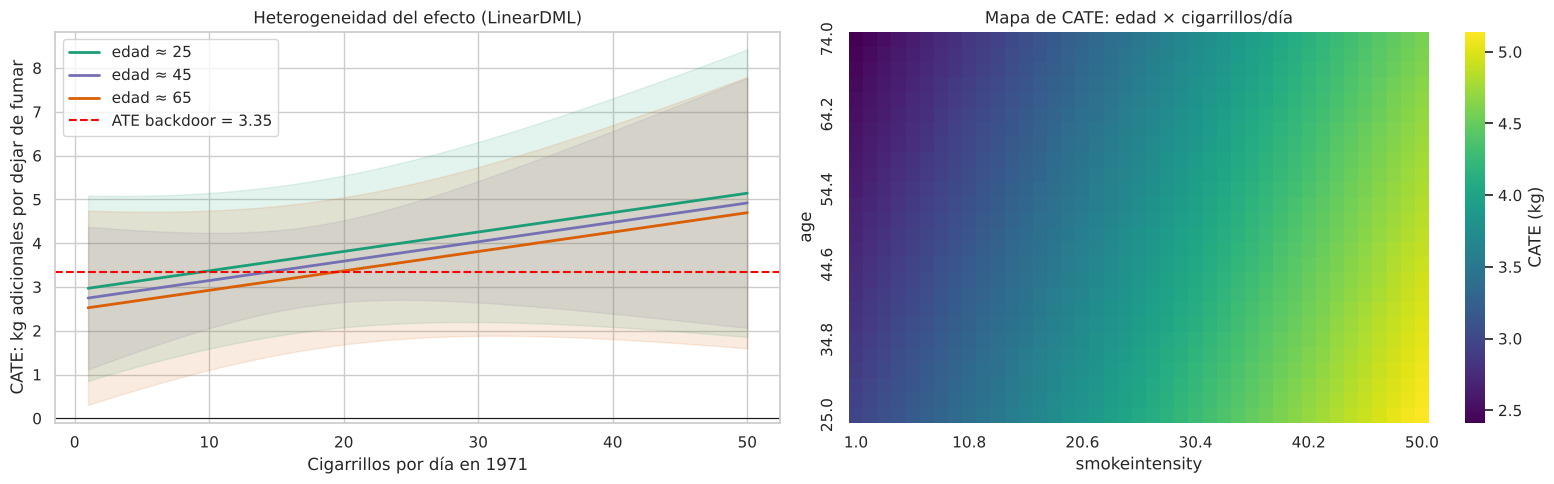

In [30]:
grid = pd.DataFrame(res_c["cate_grid"])
dml_c = res_c["dml"]
print(f"CATE lineal: τ(x) = {dml_c['intercepto']:.3f} + {dml_c['coef']['smokeintensity']:.4f}·cigarrillos/día + {dml_c['coef']['age']:.4f}·edad")
for k, v in dml_c["coef_ic"].items():
    print(f"  IC95 del coeficiente de {k}: [{v[0]:.4f}; {v[1]:.4f}]")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for edad, col in zip([25, 45, 65], ["#1b9e77", "#7570b3", "#d95f02"]):
    g = grid[np.isclose(grid["age"], grid["age"].unique()[np.argmin(np.abs(grid["age"].unique() - edad))])]
    axes[0].plot(g["smokeintensity"], g["cate"], color=col, lw=2, label=f"edad ≈ {edad}")
    axes[0].fill_between(g["smokeintensity"], g["ic_inf"], g["ic_sup"], color=col, alpha=0.12)
axes[0].axhline(res_c["ols"]["ate"], color="red", ls="--", label=f"ATE backdoor = {res_c['ols']['ate']:.2f}"); axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("Cigarrillos por día en 1971"); axes[0].set_ylabel("CATE: kg adicionales por dejar de fumar"); axes[0].set_title("Heterogeneidad del efecto (LinearDML)"); axes[0].legend()
piv = grid.pivot_table(index="age", columns="smokeintensity", values="cate")
sns.heatmap(piv.iloc[::-1], cmap="viridis", ax=axes[1], cbar_kws={"label": "CATE (kg)"}, xticklabels=8, yticklabels=5)
axes[1].set_title("Mapa de CATE: edad × cigarrillos/día"); plt.tight_layout(); plt.show()

### 4.3 · Interpretación de la estimación, DML y refutaciones


- **Paso 2 (Identify):** DoWhy identifica el efecto por *backdoor* con los 9 confusores: el estimando $\frac{d}{dT}E[Y \mid Z]$ es la notación de $E_Z\big[E(Y \mid T=1, Z) - E(Y \mid T=0, Z)\big]$, es decir, comparar dentro de cada perfil de confusores y promediar según la distribución poblacional de Z. También propone un estimando de **variable instrumental** (precio del tabaco), pero la primera etapa tiene **F = 0,38**, muy por debajo de 10: el instrumento es **débil** y su estimación (−26,9 kg) no es informativa. Por eso no sirve para contrastar el supuesto de no confusión.
- **Paso 3 (Estimate):** el ATE ajustado es **3,35 kg (IC 95%: 2,48 a 4,21)** por regresión y **3,28 kg (IC bootstrap: 2,37 a 4,34)** por IPW. El estimador ingenuo (2,54 kg) **subestima el efecto en 0,81 kg (−24%)**: el sesgo de confusión es **negativo**. Quienes dejaron de fumar eran mayores, y la edad reduce el aumento de peso, lo que "esconde" parte del efecto real. Las especificaciones alternativas coinciden: MCO flexible con términos cuadráticos **3,46 kg** (igual al valor de referencia de Hernán & Robins para estos datos), IPCW 3,35 kg y Double ML **3,62 kg (IC 95%: 2,67 a 4,57)**. El rango completo es 3,0 a 3,6 kg.
- **Paso 4 (Refute):** las tres pruebas dan **semáforo verde**:
  - causa común aleatoria: 3,350 kg (p = 0,90);
  - placebo: el efecto colapsa a −0,03 kg (p = 0,88);
  - subconjuntos del 80%: 3,334 kg (p = 0,98), dentro del IC original.

  En refutación, un p alto significa robustez. Ninguna de las pruebas puede descartar al confusor latente U.
- **Double ML y CATE:** $\hat\tau(x) = 3{,}21 + 0{,}044 \cdot \text{cig/día} - 0{,}011 \cdot \text{edad}$. El signo apoya la hipótesis H-b (más aumento de peso en los fumadores intensos: +0,44 kg cada 10 cigarrillos/día), pero **los IC de ambos coeficientes incluyen al 0**: no hay evidencia de heterogeneidad significativa. Ningún subgrupo del soporte tiene un efecto neutro: el aumento de peso estimado va de ≈ 2,5 a ≈ 5 kg y es positivo en todos los perfiles.
- **Implicancia para la decisión:** planificar el apoyo nutricional para **todos** los que dejan, con una expectativa de **≈ 3,4 kg en 11 años**. Una priorización de los fumadores intensos es razonable como hipótesis, pero estos datos no alcanzan para justificarla.

<a id="ensayo"></a>
---
# 5. Ensayo crítico: el choque entre capacidad predictiva y palanca causal

In [31]:
d_death = d.copy()
naive_death = d_death.groupby("qsmk")["death"].mean()
m_death_naive = smf.ols("death ~ qsmk", d_death).fit()
m_death_adj = smf.ols("death ~ qsmk + " + causal.FORMULA_Z, d_death).fit()
print(f"Mortalidad observada: dejó de fumar {naive_death[1]:.1%} vs. siguió fumando {naive_death[0]:.1%}  → asociación cruda {100*m_death_naive.params['qsmk']:+.1f} p.p.")
print(f"Efecto ajustado por backdoor (diferencia de riesgos): {100*m_death_adj.params['qsmk']:+.1f} p.p. "
      f"(IC95 {100*m_death_adj.conf_int().loc['qsmk',0]:+.1f}; {100*m_death_adj.conf_int().loc['qsmk',1]:+.1f})")
print(f"Variable con mayor importancia por permutación en el RF de mortalidad: {perm_s.idxmax()} (ΔAUC = {perm_s.max():.3f})")

Mortalidad observada: dejó de fumar 23.8% vs. siguió fumando 18.0%  → asociación cruda +5.8 p.p.
Efecto ajustado por backdoor (diferencia de riesgos): +0.5 p.p. (IC95 -3.4; +4.5)
Variable con mayor importancia por permutación en el RF de mortalidad: age (ΔAUC = 0.085)


**1. Si la variable más importante del Random Forest es la edad, ¿es una palanca para intervenir?** No, por dos razones:
- La edad **no es manipulable**: no existe $do(\text{edad} = x)$. Sirve para **seleccionar** a quién priorizar, no para **intervenir**.
- Aunque una variable sea manipulable, su importancia predictiva (MDI o permutación) mide cuánto ayuda a **ordenar** los casos bajo la distribución observada, $P(Y \mid X)$. No dice qué pasaría al **cambiarla**, $P(Y \mid do(X))$. La importancia por permutación rompe la asociación de X con Y y con el resto de las variables en el **modelo**, no en el **mundo**.

**2. ¿Cuándo una variable muy predictiva no tiene poder causal, o lo tiene de signo opuesto?**
- cuando su asociación con Y se debe a una **causa común** (confusión);
- cuando hay **causalidad inversa** (Y, o sus precursores, causan X);
- cuando X es un **marcador o proxy** de la causa real;
- cuando la muestra fue **seleccionada** por un colisionador.

Los datos de este trabajo tienen un ejemplo de manual. Entre quienes **dejaron de fumar**, la mortalidad observada fue **23,8%**, contra **18,0%** entre quienes siguieron: +5,8 puntos porcentuales. Un modelo predictivo puede usar `qsmk` como señal de **mayor** riesgo. Pero al ajustar por los confusores, el efecto de dejar de fumar sobre la mortalidad cae a **+0,5 p.p. (IC 95%: −3,4 a +4,5)**, compatible con cero. La asociación cruda viene de que quienes dejan son **mayores** (H2) y, plausiblemente, del efecto "*sick quitter*" (dejar tras un diagnóstico: causalidad inversa no medida).

Un directorio que "optimizara" la mortalidad leyendo el modelo predictivo concluiría que **conviene desalentar la cesación**: una política no solo inútil sino dañina, porque la evidencia médica de largo plazo muestra que dejar de fumar reduce la mortalidad. El ANOVA de la Fase 1 muestra un caso parecido: la educación "predice" menos aumento de peso, pero el grupo de menor educación es también el de mayor edad.

**Conclusión:** la Fase 3 responde **a quién mirar** (riesgo) y la Fase 4 responde **qué pasa si actuamos** (efecto). Mezclarlas lleva a optimizar correlaciones espurias. Toda palanca de política tiene que pasar por un DAG explícito, un criterio de identificación y pruebas de refutación antes de llegar a la mesa de decisión.

<a id="conclusiones"></a>
---
# 6. Conclusiones, recomendaciones y limitaciones


**Hallazgos**
1. **Calidad de datos:** se detectó un bloque oculto de faltantes **por diseño** (48,6%, cambio de cuestionario), faltantes estructurales y una censura del resultado causal que **no es MCAR** (se corrigió con IPCW, bajo el supuesto MAR).
2. **Inferencia clásica:** quienes dejan de fumar ganan 2,5 kg más en bruto, pero son 3,4 años mayores y fuman menos: hay autoselección. El ANOVA de Welch encuentra diferencias por educación (p = 0,002) de magnitud muy chica (η² = 1,1%).
3. **Modelo lineal:** hay heterocedasticidad y colas pesadas (se usó HC3 y Huber como sensibilidad), sin puntos con influencia excesiva (Cook máximo 0,03). La colinealidad se resolvió eliminando `school` y reemplazando `smokeyrs` por la edad de inicio. Los 3 componentes principales tienen interpretación clara (envejecimiento, tamaño corporal, nivel socioeconómico).
4. **Predicción de mortalidad:** la logística regularizada y calibrada logra **AUC 0,85 y Brier 0,117**, a la par del Random Forest y mucho mejor que Naive Bayes, al que la dependencia entre predictores lo vuelve sobreconfiado.
5. **Efecto causal:** dejar de fumar **causa un aumento de ≈ 3,4 kg en 11 años (IC 95%: 2,5 a 4,2)**. Los métodos coinciden (de 3,0 a 3,6 kg según el estimador) y pasan las tres refutaciones. El análisis ingenuo lo subestimaba un 24%. No se encontró heterogeneidad significativa por intensidad de consumo ni por edad.

**Recomendaciones para el programa de cesación**
- **Incluir apoyo nutricional y de actividad física para todos los que dejen**, con una meta comunicada realista: **≈ 3–4 kg de aumento esperado en 11 años**. Es un costo de salud mucho menor que el de seguir fumando.
- **Priorizar el reclutamiento con el modelo de riesgo** (edad, años fumando, sexo). Al usar probabilidades calibradas, se puede presupuestar el número esperado de eventos por segmento.
- **No usar la mortalidad cruda de quienes dejan** como indicador del programa: está confundida por edad y por el efecto *sick quitter*.
- **Validar la hipótesis de mayor aumento de peso en fumadores intensos** con un diseño experimental o una muestra mayor antes de diferenciar la intervención.

**Limitaciones y amenazas a la validez**
- La no confusión no se puede verificar: la "conciencia de salud" (U) podría sesgar el resultado, y el instrumento disponible es débil.
- La censura podría ser MNAR (los censurados murieron más).
- El mediador (dieta) no está medido.
- La cohorte es de EE. UU. en los años 70.
- El CATE se modeló como lineal.
- La mortalidad se observa en una ventana de 10 años.

In [32]:
# Artefactos para la web app (mismos objetos y semillas que este notebook)
info = {"modelo": "Regresión logística regularizada y calibrada (sigmoide)", "C": C_final, "l1_ratio": L1_final,
        "metricas_test": pipeline.predictive_metrics(modelos["Logística calibrada (final)"], Xte, yte),
        "features": list(Xtr.columns), "medianas_train": Xtr.median(numeric_only=True).to_dict(),
        "modas_train": Xtr.mode().iloc[0].astype(str).to_dict()}
pipeline.save_artifacts(modelos["Logística calibrada (final)"], info, pca_pipe, res_c, d)
print("Artefactos guardados en", ROOT / "models")

Artefactos guardados en /home/claude/tpi/models


<a id="referencias"></a>
---
# 7. Referencias


- Hernán, M. A. & Robins, J. M. (2020). *Causal Inference: What If*. Boca Raton: Chapman & Hall/CRC. (Fuente de la versión del dataset NHEFS y del análisis de referencia.)
- National Center for Health Statistics. *NHANES I Epidemiologic Follow-up Study (NHEFS)*. Centers for Disease Control and Prevention.
- Pearl, J. (2009). *Causality: Models, Reasoning, and Inference* (2.ª ed.). Cambridge University Press.
- Pearl, J., Glymour, M. & Jewell, N. P. (2016). *Causal Inference in Statistics: A Primer*. Wiley.
- Chernozhukov, V. et al. (2018). Double/debiased machine learning for treatment and structural parameters. *The Econometrics Journal*, 21(1), C1–C68.
- Sharma, A. & Kiciman, E. (2020). DoWhy: An end-to-end library for causal inference. *arXiv:2011.04216*.
- Battocchi, K. et al. (2019). *EconML: A Python package for ML-based heterogeneous treatment effects estimation*. Microsoft Research.
- Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32.
- Strobl, C., Boulesteix, A.-L., Zeileis, A. & Hothorn, T. (2007). Bias in random forest variable importance measures. *BMC Bioinformatics*, 8, 25.
- Niculescu-Mizil, A. & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of ICML*.
- Little, R. J. A. & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3.ª ed.). Wiley.
- Welch, B. L. (1951). On the comparison of several mean values: an alternative approach. *Biometrika*, 38, 330–336.
- Breusch, T. S. & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica*, 47(5), 1287–1294.
- Cook, R. D. (1977). Detection of influential observation in linear regression. *Technometrics*, 19(1), 15–18.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
- Seabold, S. & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.